##Gold Price Forecasting Using Historical Commodity Prices (Time Series Analysis): A Comparative Study of Machine Learning and Deep Learning Models

Import Libraries and Download Historical Commodity Data from Yahoo Finance

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = {
    "Gold": "GC=F",
    "Silver": "SI=F",
    "Platinum": "PL=F",
    "Palladium": "PA=F",
    "Crude_Oil": "CL=F"
}

start_date = "2010-01-01"
end_date = "2026-03-31"  # Exclusive, so data includes March 30, 2026

data = yf.download(
    list(tickers.values()),
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    progress=False,
    group_by="column"
)

print("Downloaded data shape:", data.shape)
print(data.head())
print(data.tail())

Downloaded data shape: (4085, 30)
Price       Adj Close                                                   \
Ticker           CL=F         GC=F        PA=F         PL=F       SI=F   
Date                                                                     
2010-01-04  81.510002  1117.699951  419.799988  1517.300049  17.440001   
2010-01-05  81.769997  1118.099976  420.350006  1530.800049  17.781000   
2010-01-06  83.180000  1135.900024  425.600006  1552.199951  18.163000   
2010-01-07  82.660004  1133.099976  422.950012  1553.000000  18.333000   
2010-01-08  82.750000  1138.199951  424.149994  1564.599976  18.458000   

Price           Close                                                   ...  \
Ticker           CL=F         GC=F        PA=F         PL=F       SI=F  ...   
Date                                                                    ...   
2010-01-04  81.510002  1117.699951  419.799988  1517.300049  17.440001  ...   
2010-01-05  81.769997  1118.099976  420.350006  1530.8000

Download the raw dataset CSV

In [2]:
# Save raw Yahoo Finance data to CSV
raw_file = "gold_commodities_raw_2010_2026.csv"

data.to_csv(raw_file)

print("Raw dataset saved:", raw_file)

# Download the CSV file in Google Colab
from google.colab import files
files.download(raw_file)

Raw dataset saved: gold_commodities_raw_2010_2026.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Extract and align the prices

In [3]:
# Extract closing prices
close_prices = data["Close"].copy()

# Rename ticker symbols to commodity names
close_prices = close_prices.rename(
    columns={
        symbol: name
        for name, symbol in tickers.items()
    }
)

# Standardise and sort dates
close_prices.index = pd.to_datetime(close_prices.index)
close_prices = close_prices.sort_index()
close_prices.index.name = "Date"

# Remove rows where all commodity prices are missing
close_prices = close_prices.dropna(how="all")

# Display date range
print("Available date range:")
print(close_prices.index.min(), "to", close_prices.index.max())

# Display missing values
print("\nMissing values:")
print(close_prices.isna().sum())

# Display observations per commodity
print("\nObservations per commodity:")
print(close_prices.notna().sum())

Available date range:
2010-01-04 00:00:00 to 2026-03-30 00:00:00

Missing values:
Ticker
Crude_Oil     1
Gold          1
Palladium    20
Platinum      3
Silver        2
dtype: int64

Observations per commodity:
Ticker
Crude_Oil    4084
Gold         4084
Palladium    4065
Platinum     4082
Silver       4083
dtype: int64


DATA CLEANING

Handle missing values and download the final dataset

In [4]:
# Create the final modelling dataset
dataset = close_prices.dropna().copy()
dataset.index.name = "Date"

# Check the final dataset
print("Final dataset shape:", dataset.shape)

print("\nDate range:")
print(dataset.index.min(), "to", dataset.index.max())

print("\nMissing values:")
print(dataset.isna().sum())

print("\nFirst 5 rows:")
print(dataset.head())

print("\nLast 5 rows:")
print(dataset.tail())

# Save without downloading again
final_file = "/content/gold_commodities_final_cleaned_2010_2026.csv"
dataset.to_csv(final_file)

print("\nFinal cleaned dataset saved:", final_file)

Final dataset shape: (4065, 5)

Date range:
2010-01-04 00:00:00 to 2026-03-30 00:00:00

Missing values:
Ticker
Crude_Oil    0
Gold         0
Palladium    0
Platinum     0
Silver       0
dtype: int64

First 5 rows:
Ticker      Crude_Oil         Gold   Palladium     Platinum     Silver
Date                                                                  
2010-01-04  81.510002  1117.699951  419.799988  1517.300049  17.440001
2010-01-05  81.769997  1118.099976  420.350006  1530.800049  17.781000
2010-01-06  83.180000  1135.900024  425.600006  1552.199951  18.163000
2010-01-07  82.660004  1133.099976  422.950012  1553.000000  18.333000
2010-01-08  82.750000  1138.199951  424.149994  1564.599976  18.458000

Last 5 rows:
Ticker       Crude_Oil         Gold    Palladium     Platinum     Silver
Date                                                                    
2026-03-24   92.349998  4402.000000  1411.199951  1892.000000  69.274002
2026-03-25   90.320000  4552.299805  1416.000000  1925.1

Inspect the final cleaned dataset

In [5]:
# FINAL DATASET INSPECTION

print("GOLD AND COMMODITY PRICE FORECASTING - DATASET INSPECTION")

print("\n1. Dataset dimensions:")
print(f"Rows: {dataset.shape[0]:,}")
print(f"Columns: {dataset.shape[1]}")

print("\n2. Date range:")
print(f"Start date: {dataset.index.min().date()}")
print(f"End date:   {dataset.index.max().date()}")

print("\n3. Column names:")
print(dataset.columns.tolist())

print("\n4. Data types:")
print(dataset.dtypes)

print("\n5. Missing values:")
print(dataset.isna().sum())

print("\n6. Duplicate dates:")
print(dataset.index.duplicated().sum())

print("\n7. Duplicate rows:")
print(dataset.duplicated().sum())

print("\n8. First five observations:")
display(dataset.head())

print("\n9. Last five observations:")
display(dataset.tail())

print("\n10. Descriptive statistics:")
display(dataset.describe().T.round(2))


GOLD AND COMMODITY PRICE FORECASTING - DATASET INSPECTION

1. Dataset dimensions:
Rows: 4,065
Columns: 5

2. Date range:
Start date: 2010-01-04
End date:   2026-03-30

3. Column names:
['Crude_Oil', 'Gold', 'Palladium', 'Platinum', 'Silver']

4. Data types:
Ticker
Crude_Oil    float64
Gold         float64
Palladium    float64
Platinum     float64
Silver       float64
dtype: object

5. Missing values:
Ticker
Crude_Oil    0
Gold         0
Palladium    0
Platinum     0
Silver       0
dtype: int64

6. Duplicate dates:
0

7. Duplicate rows:
0

8. First five observations:


Ticker,Crude_Oil,Gold,Palladium,Platinum,Silver
Date,,,,,
2010-01-04,81.510002,1117.699951,419.799988,1517.300049,17.440001
2010-01-05,81.769997,1118.099976,420.350006,1530.800049,17.781000
2010-01-06,83.180000,1135.900024,425.600006,1552.199951,18.163000
2010-01-07,82.660004,1133.099976,422.950012,1553.000000,18.333000
2010-01-08,82.750000,1138.199951,424.149994,1564.599976,18.458000



9. Last five observations:


Ticker,Crude_Oil,Gold,Palladium,Platinum,Silver
Date,,,,,
2026-03-24,92.349998,4402.000000,1411.199951,1892.000000,69.274002
2026-03-25,90.320000,4552.299805,1416.000000,1925.199951,72.361000
2026-03-26,94.480003,4376.299805,1341.300049,1838.300049,67.670998
2026-03-27,99.639999,4492.500000,1390.900024,1870.599976,69.544998
2026-03-30,102.879997,4526.000000,1418.000000,1885.599976,70.323997



10. Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
Crude_Oil,4065.0,71.55,20.76,-37.63,54.69,71.34,88.32,123.70
Gold,4065.0,1716.97,703.47,1050.80,1272.20,1526.50,1847.80,5318.40
Palladium,4065.0,1155.32,602.36,407.95,718.25,931.95,1492.30,2985.40
Platinum,4065.0,1179.33,329.74,595.90,931.00,1018.90,1452.00,2852.40
Silver,4065.0,24.07,10.79,11.73,17.06,21.62,28.02,115.08


EDA(Exploratory Data Analysis)

GOLD PRICE LINE PLOT

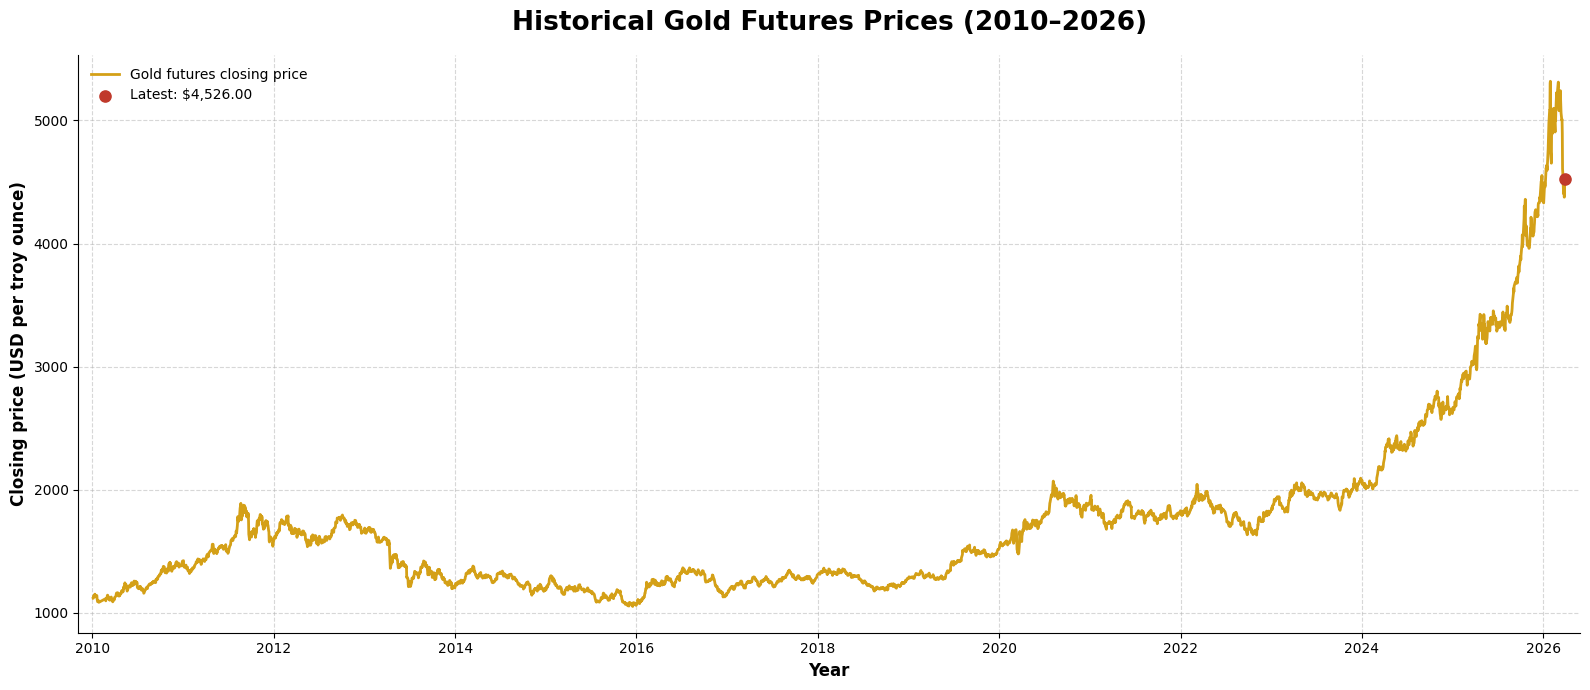

Minimum gold price: $1,050.80
Maximum gold price: $5,318.40
Latest gold price:  $4,526.00


In [6]:
# GOLD PRICE LINE PLOT

gold = dataset["Gold"].dropna()

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    gold.index,
    gold.values,
    color="#D4A017",
    linewidth=2.0,
    label="Gold futures closing price"
)

# Highlight the latest observation
ax.scatter(
    gold.index[-1],
    gold.iloc[-1],
    color="#C0392B",
    s=65,
    zorder=5,
    label=f"Latest: ${gold.iloc[-1]:,.2f}"
)

ax.set_title(
    "Historical Gold Futures Prices (2010–2026)",
    fontsize=19,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=12, fontweight="bold")
ax.set_ylabel("Closing price (USD per troy ounce)", fontsize=12, fontweight="bold")

ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=False, fontsize=10)
ax.margins(x=0.01)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Minimum gold price: ${gold.min():,.2f}")
print(f"Maximum gold price: ${gold.max():,.2f}")
print(f"Latest gold price:  ${gold.iloc[-1]:,.2f}")

**Analysis**: Gold futures prices show a strong overall upward trend from 2010 to 2026, with periods of decline and volatility. Growth accelerated sharply from 2024, reaching a latest plotted price of approximately $4,526 per troy ounce.

Gold Futures Price Trend (2010–2026): Effects of the 2008 Financial Crisis, COVID-19 Pandemic, and 2022 Russia–Ukraine War

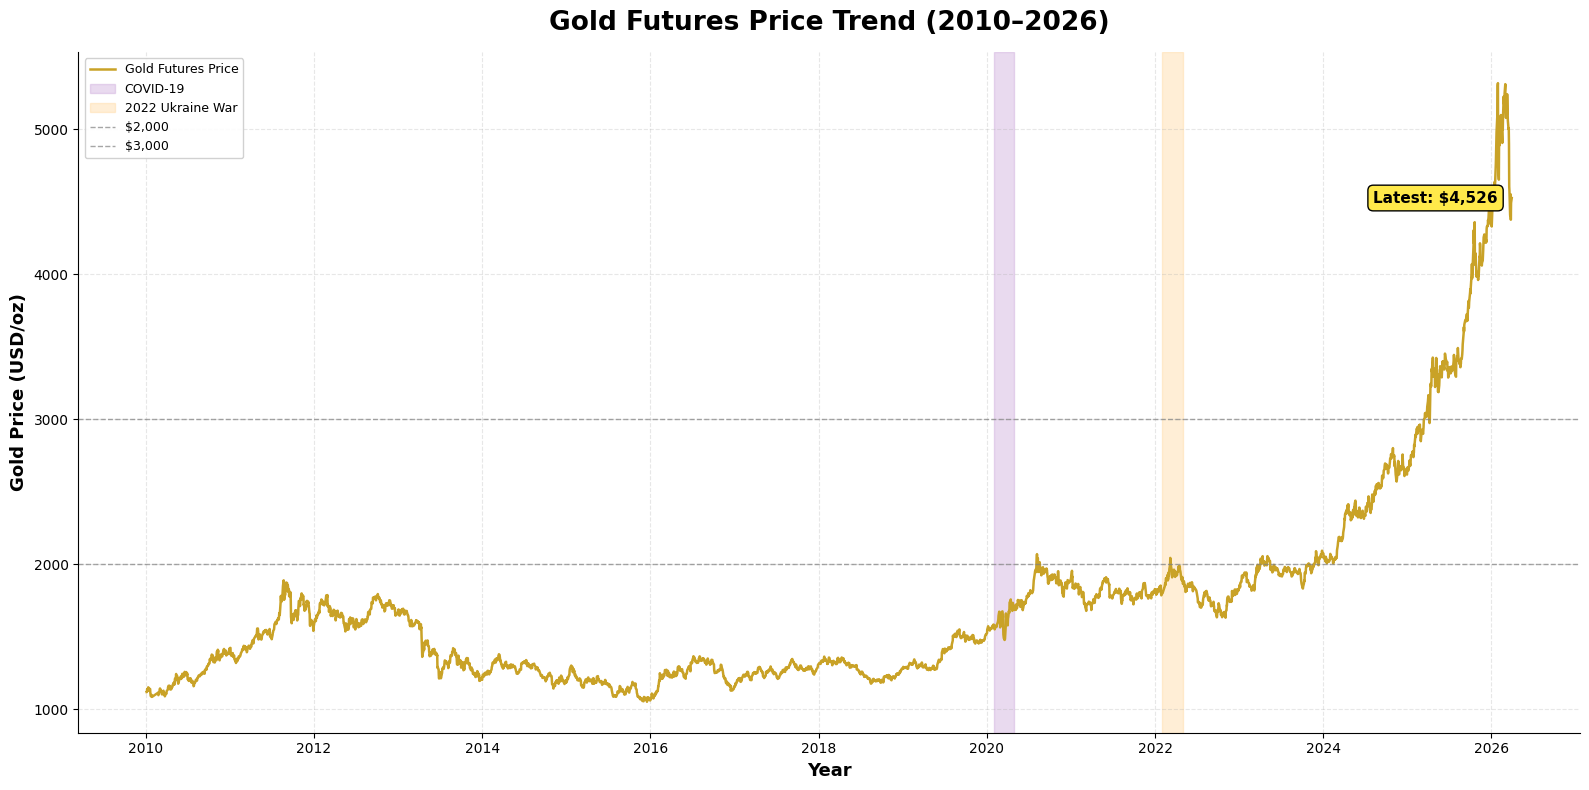

In [7]:
import matplotlib.dates as mdates

# Gold futures closing prices
gold = dataset["Gold"].dropna()

fig, ax = plt.subplots(figsize=(16, 8))

# Gold price line
ax.plot(
    gold.index,
    gold.values,
    color="#C9A227",
    linewidth=1.8,
    label="Gold Futures Price"
)

# Highlight selected historical periods
periods = [
    ("2020-02-01", "2020-04-30", "COVID-19", "#C9A3D8"),
    ("2022-02-01", "2022-04-30", "2022 Ukraine War", "#FFD699")
]

for start, end, label, color in periods:
    ax.axvspan(
        pd.Timestamp(start),
        pd.Timestamp(end),
        color=color,
        alpha=0.4,
        label=label
    )

# Horizontal reference lines
for level in [2000, 3000]:
    ax.axhline(
        y=level,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
        label=f"${level:,.0f}"
    )

# Latest price annotation
latest_date = gold.index[-1]
latest_price = gold.iloc[-1]

ax.annotate(
    f"Latest: ${latest_price:,.0f}",
    xy=(latest_date, latest_price),
    xytext=(-10, 0),
    textcoords="offset points",
    ha="right",
    va="center",
    fontsize=11,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="#FFE94A",
        edgecolor="black"
    ),
    annotation_clip=False
)

# Display years on the X-axis
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Titles and formatting
ax.set_title(
    "Gold Futures Price Trend (2010–2026)",
    fontsize=19,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Year", fontsize=13, fontweight="bold")
ax.set_ylabel("Gold Price (USD/oz)", fontsize=13, fontweight="bold")

ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left", fontsize=9, framealpha=0.9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Analysis**: Gold futures prices show a strong long-term upward trend from 2010 to 2026, despite several periods of volatility and correction. Prices declined after peaking around 2011–2012 and remained relatively stable for several years. Further growth occurred around the COVID-19 period, followed by fluctuations during 2022–2023. A sharp rise from 2024 pushed prices above
5,000 before the latest observed value of approximately $4,526 per troy ounce. These movements highlight long-term growth and changing market volatility.

Combined line plot of all five commodities

The next plot shows all five original closing-price series together. Because each commodity has a different price scale, some lines may appear much flatter than others.

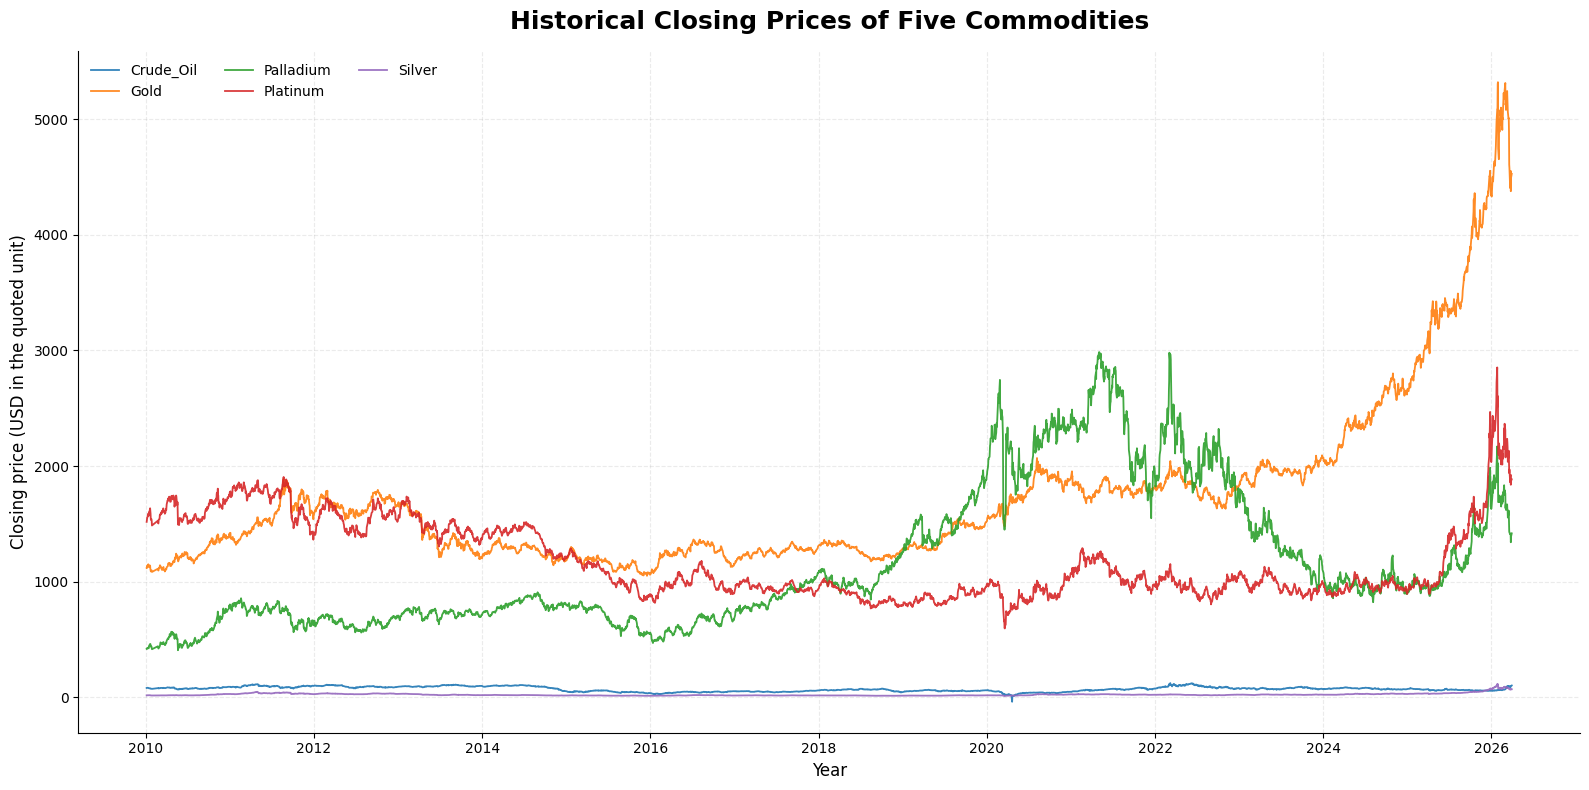

In [8]:
# COMBINED COMMODITY PRICE PLOT

fig, ax = plt.subplots(figsize=(16, 8))

for commodity in dataset.columns:
    ax.plot(
        dataset.index,
        dataset[commodity],
        linewidth=1.3,
        alpha=0.9,
        label=commodity
    )

ax.set_title(
    "Historical Closing Prices of Five Commodities",
    fontsize=18,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Closing price (USD in the quoted unit)", fontsize=12)

ax.grid(True, linestyle="--", alpha=0.25)
ax.legend(ncol=3, frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretation**: Gold shows the strongest upward trend, rising sharply from 2024 to 2026. Palladium and platinum exhibit greater fluctuations, with notable price spikes and declines, while silver and crude oil remain comparatively lower in absolute price. These differences highlight varying price trends and volatility across commodities.

Compare commodity trends on a common scale

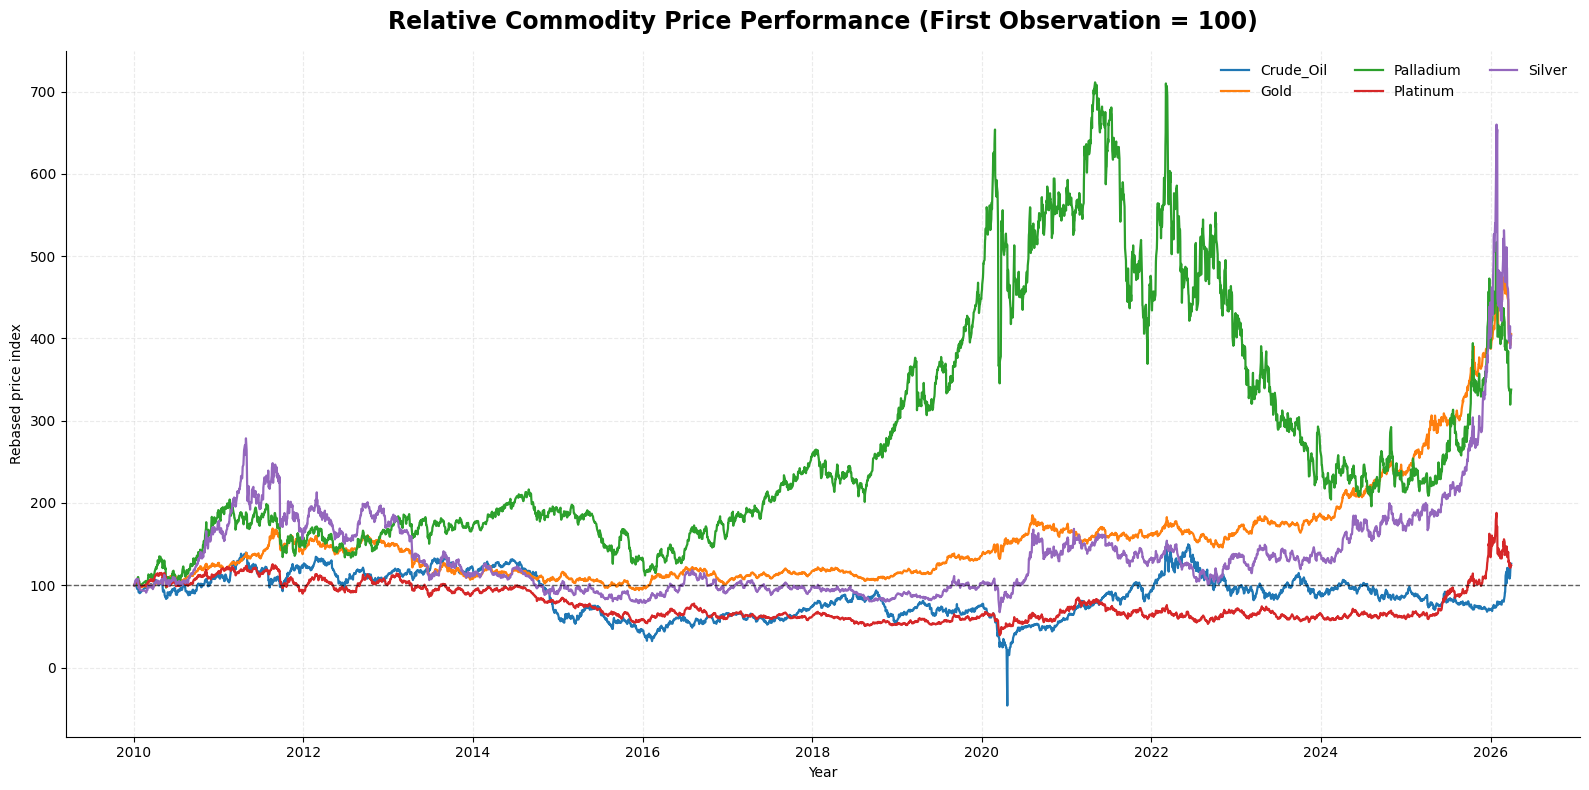

In [9]:
# NORMALISED PRICE COMPARISON


normalised_prices = dataset.div(dataset.iloc[0]).mul(100)

fig, ax = plt.subplots(figsize=(16, 8))

for commodity in normalised_prices.columns:
    ax.plot(
        normalised_prices.index,
        normalised_prices[commodity],
        linewidth=1.6,
        label=commodity
    )

ax.axhline(100, color="black", linestyle="--", linewidth=1, alpha=0.6)

ax.set_title(
    "Relative Commodity Price Performance (First Observation = 100)",
    fontsize=17,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Year")
ax.set_ylabel("Rebased price index")
ax.legend(ncol=3, frameon=False)
ax.grid(True, linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

To compare how much each commodity has changed over time, rebase all five series to 100 at the first date in the cleaned dataset.
This transformation is only for visual comparison. It does not change the original dataset or the target prices used for forecasting.

**Interpretation**: Palladium and silver show substantial relative price fluctuations, with sharp increases around 2011–2012 and 2020–2026. Gold demonstrates strong growth, particularly from 2024, while platinum and crude oil show comparatively moderate long-term gains. Overall, commodity performance varies considerably over time.

Individual commodity price plots

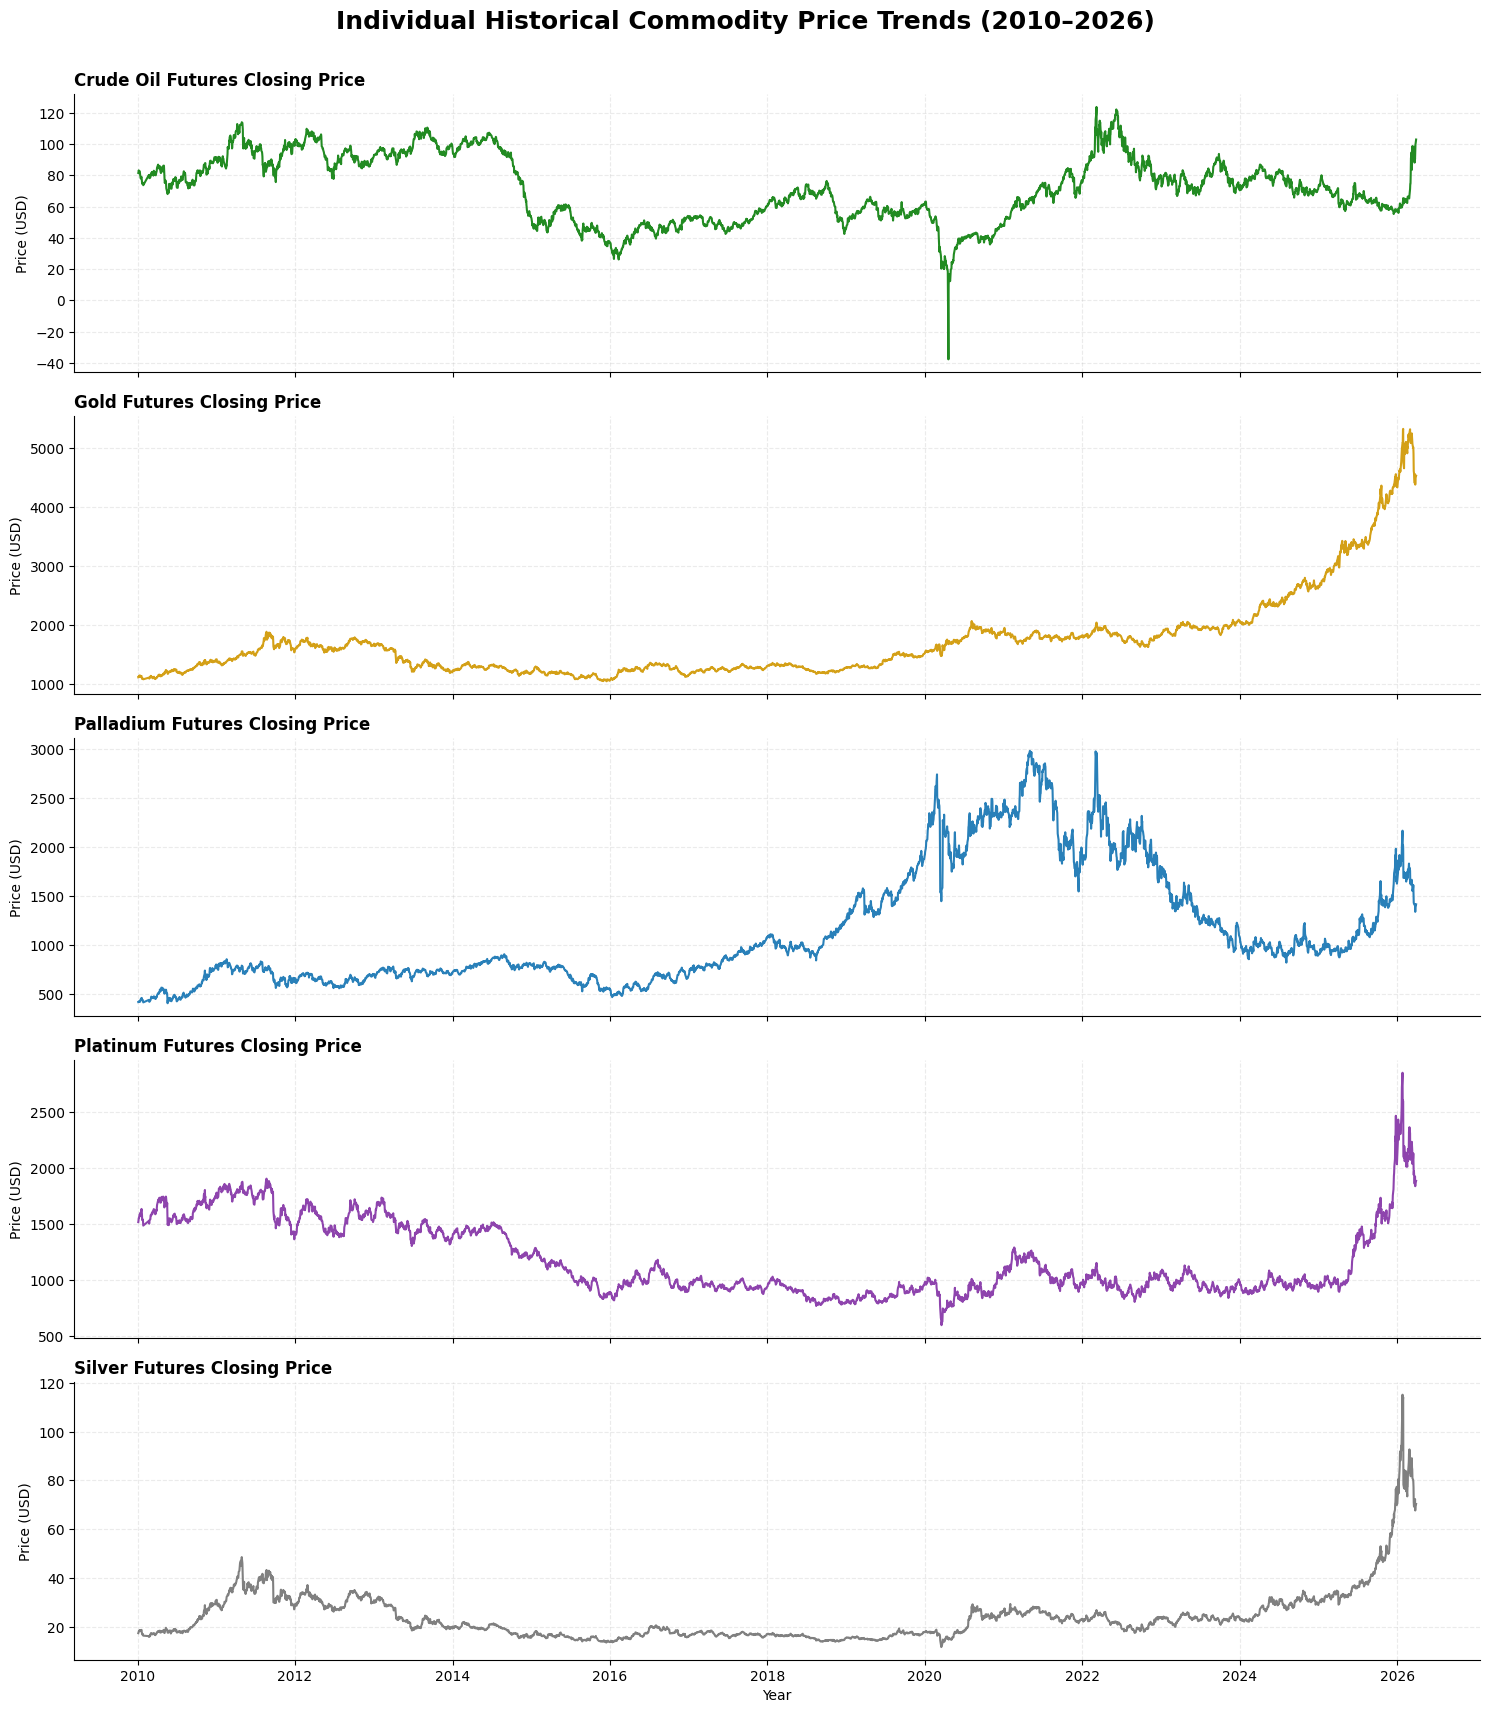

In [10]:
# INDIVIDUAL COMMODITY TRENDS

commodities = dataset.columns.tolist()

# Unique colours for each commodity
commodity_colors = {
    "Gold": "#D4A017",        # Gold
    "Silver": "#808080",      # Silver grey
    "Platinum": "#8E44AD",    # Purple
    "Palladium": "#2980B9",   # Blue
    "Crude_Oil": "#228B22"    # Green
}

fig, axes = plt.subplots(
    nrows=len(commodities),
    ncols=1,
    figsize=(15, 17),
    sharex=True
)

for ax, commodity in zip(axes, commodities):
    ax.plot(
        dataset.index,
        dataset[commodity],
        color=commodity_colors.get(commodity, "#333333"),
        linewidth=1.5
    )

    ax.set_title(
        f"{commodity.replace('_', ' ')} Futures Closing Price",
        fontsize=12,
        fontweight="bold",
        loc="left"
    )

    ax.set_ylabel("Price (USD)")
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Year")

plt.suptitle(
    "Individual Historical Commodity Price Trends (2010–2026)",
    fontsize=18,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

Price distributions

Histograms reveal the distribution of observed price levels.

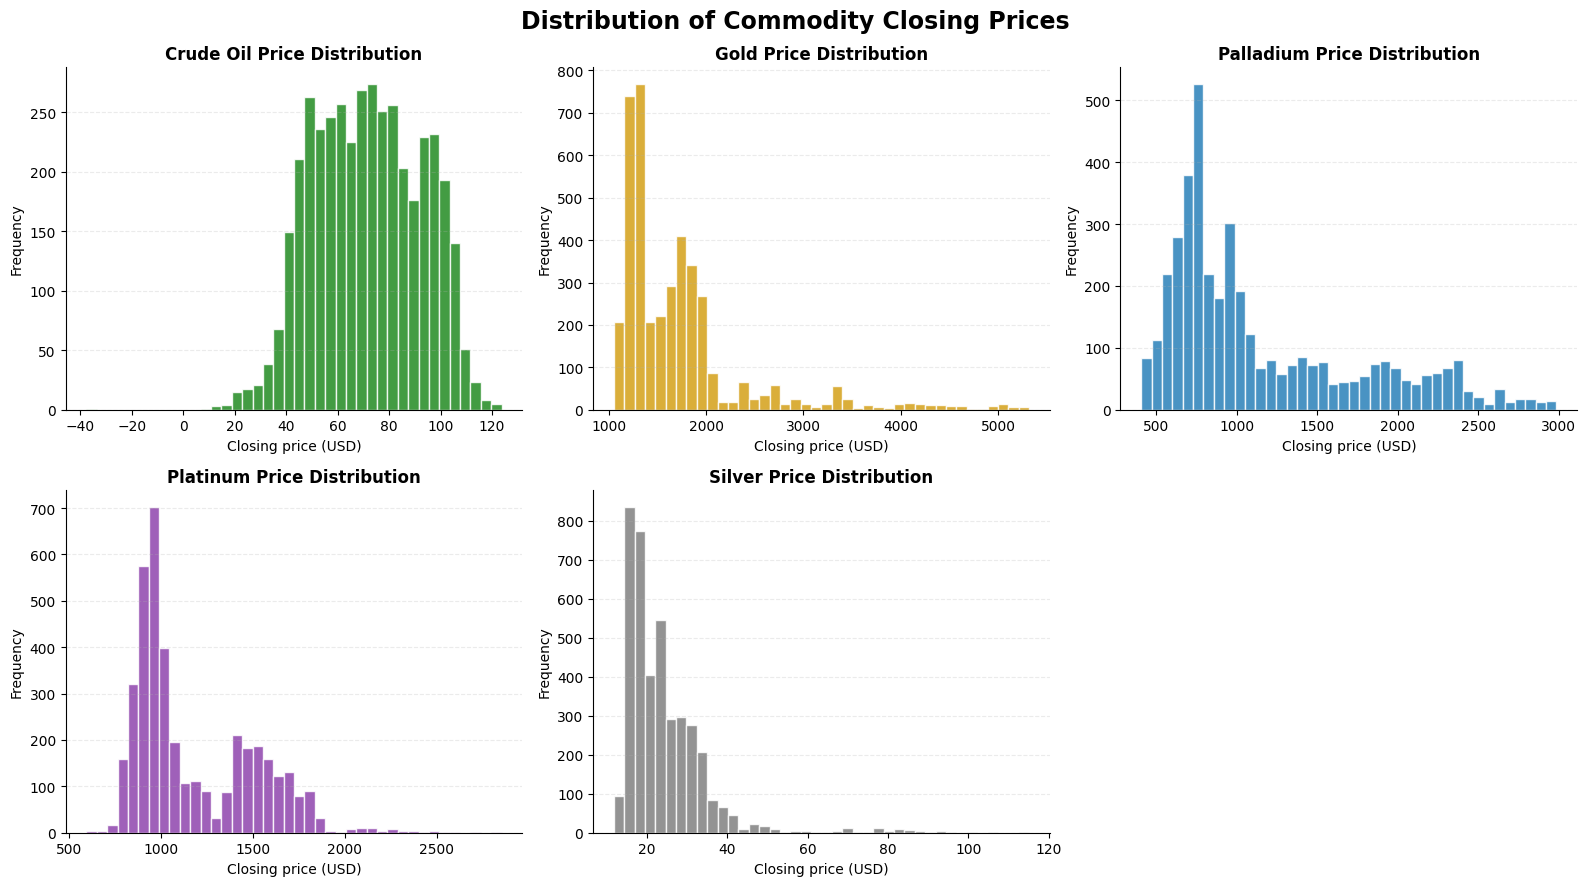

In [11]:
# PRICE DISTRIBUTIONS

commodities = dataset.columns.tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, commodity in enumerate(commodities):
    axes[i].hist(
        dataset[commodity],
        bins=40,
        color=commodity_colors[commodity],
        edgecolor="white",
        alpha=0.85
    )

    axes[i].set_title(
        f"{commodity.replace('_', ' ')} Price Distribution",
        fontweight="bold"
    )
    axes[i].set_xlabel("Closing price (USD)")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", linestyle="--", alpha=0.25)

    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

axes[-1].axis("off")

plt.suptitle(
    "Distribution of Commodity Closing Prices",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpretation**: Gold, palladium, platinum, and silver exhibit positively skewed distributions, with longer tails toward higher prices. Palladium and platinum show multiple peaks, indicating different price concentration levels. Crude oil prices are more concentrated around the middle range. Overall, the distributions highlight differences in commodity price variability and extreme market observations.

Boxplots help identify unusually high or low observations.

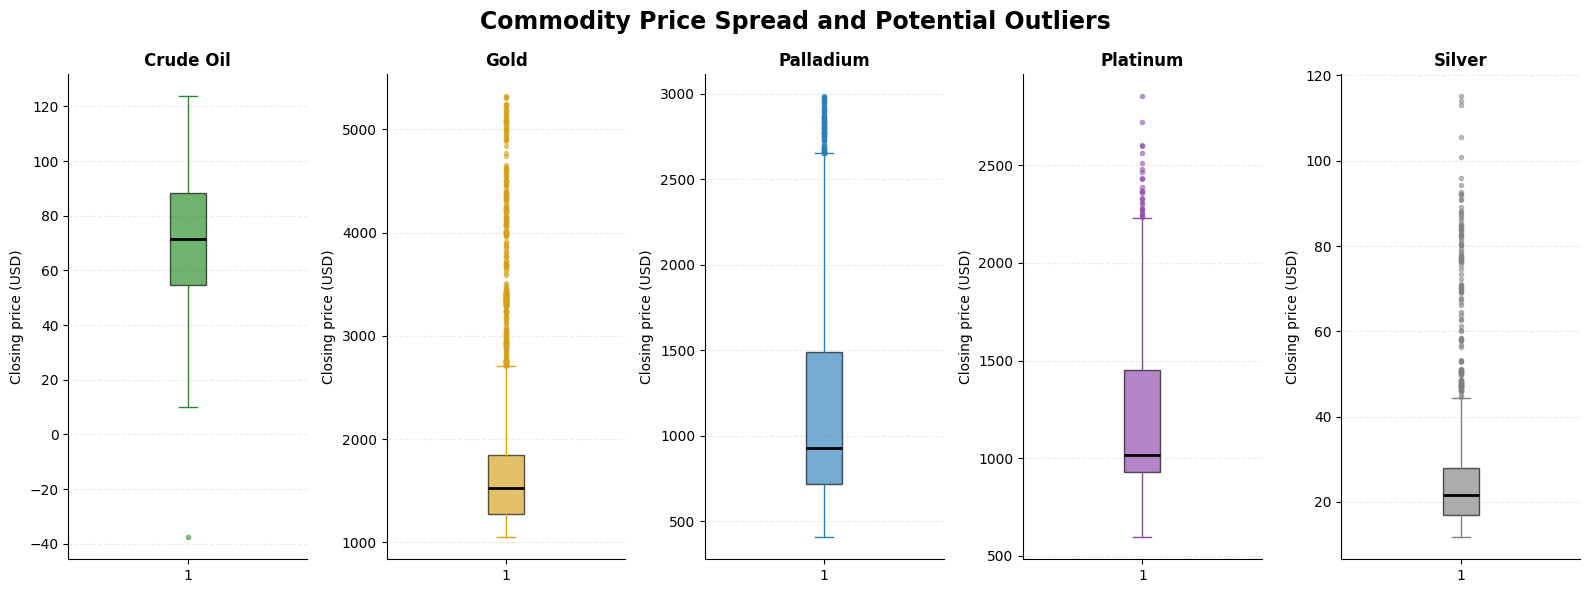

In [12]:
# PRICE BOXPLOTS

fig, axes = plt.subplots(1, len(commodities), figsize=(16, 6))

for ax, commodity in zip(axes, commodities):
    ax.boxplot(
        dataset[commodity],
        patch_artist=True,
        showfliers=True,
        boxprops=dict(
            facecolor=commodity_colors[commodity],
            alpha=0.65
        ),
        medianprops=dict(color="black", linewidth=2),
        whiskerprops=dict(color=commodity_colors[commodity]),
        capprops=dict(color=commodity_colors[commodity]),
        flierprops=dict(
            marker="o",
            markerfacecolor=commodity_colors[commodity],
            markeredgecolor=commodity_colors[commodity],
            markersize=3,
            alpha=0.5
        )
    )

    ax.set_title(commodity.replace("_", " "), fontweight="bold")
    ax.set_ylabel("Closing price (USD)")
    ax.grid(axis="y", linestyle="--", alpha=0.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Commodity Price Spread and Potential Outliers",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Analysis: Commodity Price Spread and Potential Outliers**

- **Crude Oil:** Prices are mostly concentrated between 55 and 90, with a negative outlier indicating an extreme market event.
- **Gold:** Shows numerous high-price outliers above 2,700, reflecting substantial price increases.
- **Palladium:** Exhibits considerable price variability, with high-price outliers approaching 3,000.
- **Platinum:** Shows a wide price spread, with several outliers above 2,200.
- **Silver:** Prices are concentrated at lower levels, with numerous high-price outliers exceeding 100.

**Overall Conclusion:** The commodities exhibit different levels of price variability and extreme observations. These outliers may represent genuine market events and should be investigated before removal, as they could provide valuable information for forecasting.

Daily percentage returns

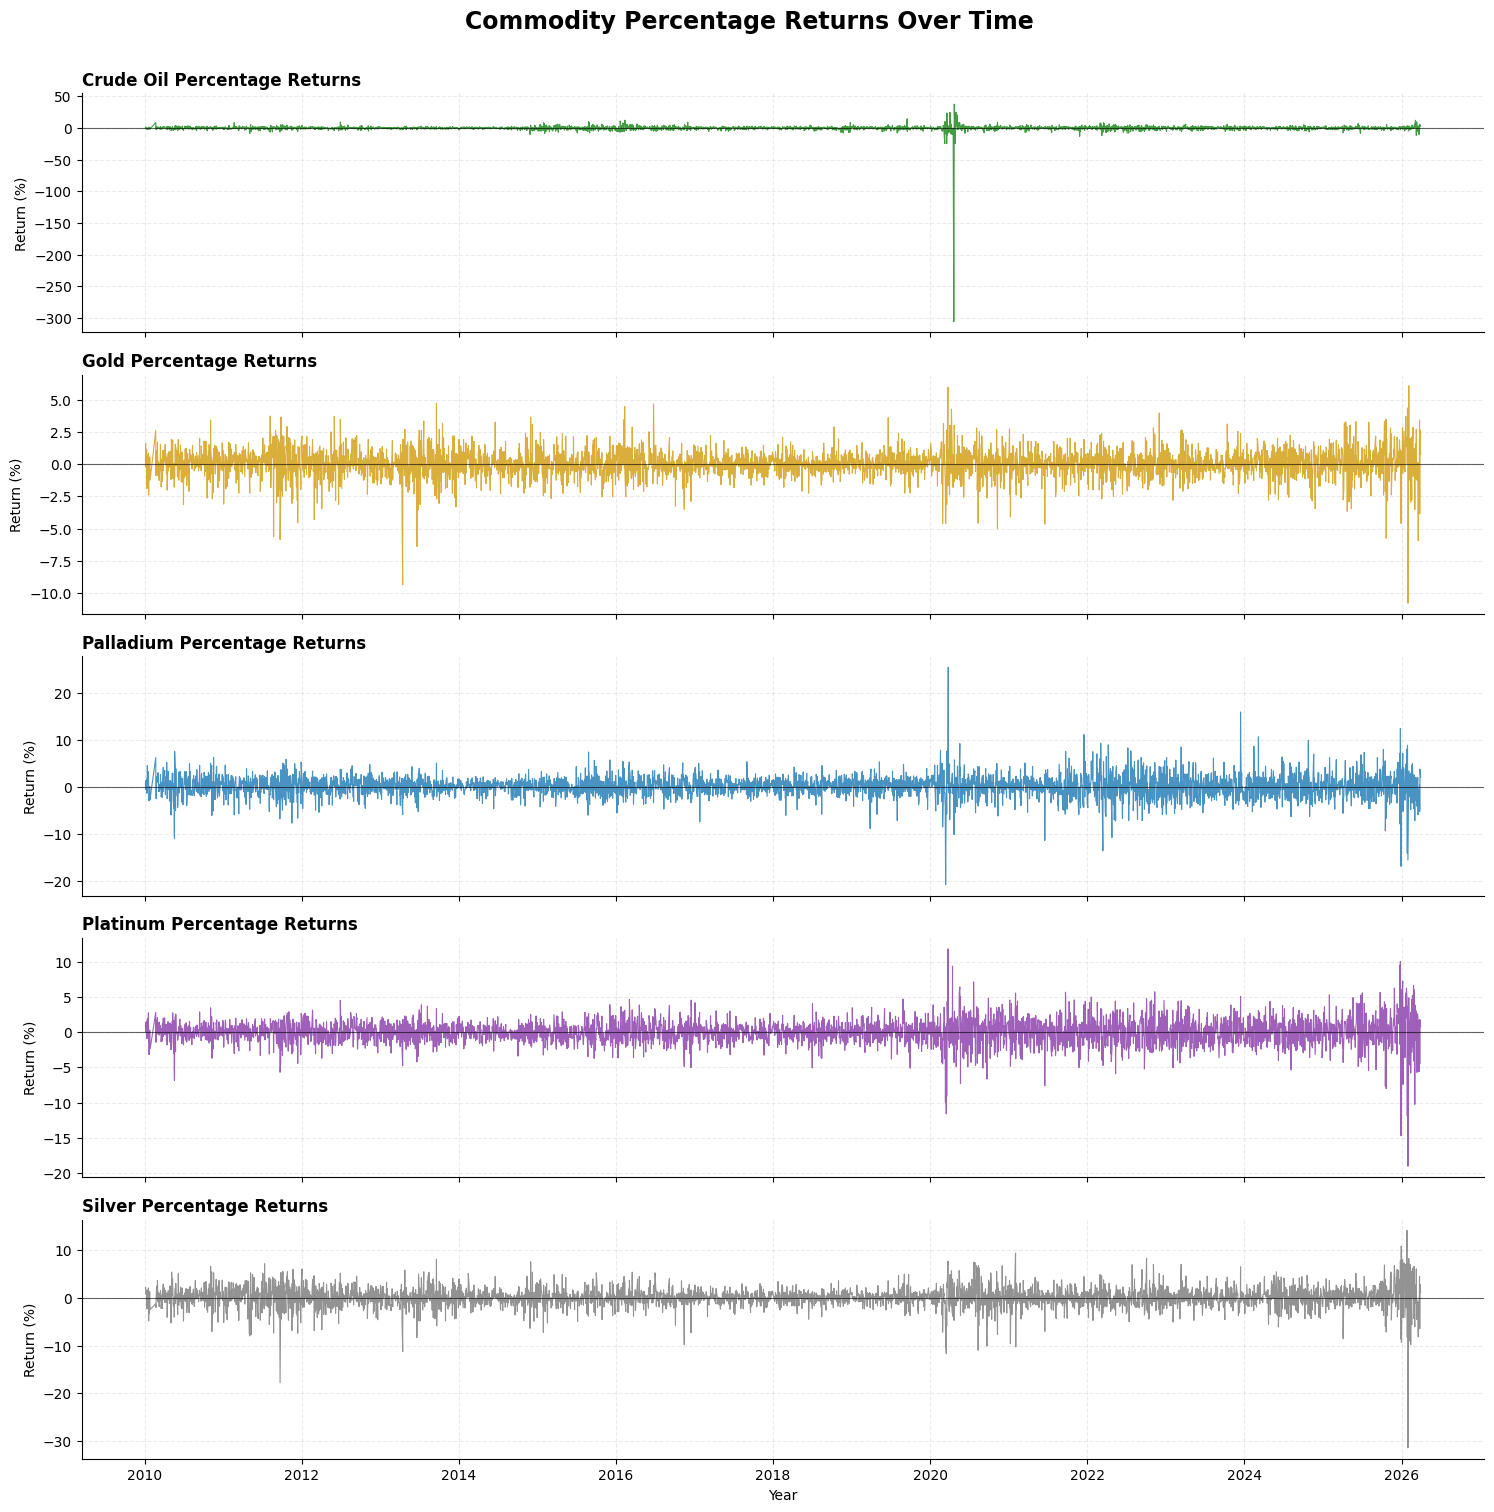

Return statistics (%):


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
Crude_Oil,4064.0,-0.0527,5.8051,-305.9661,-1.1659,0.0941,1.2427,37.6623
Gold,4064.0,0.0401,1.0681,-10.7796,-0.4585,0.0443,0.5943,6.0697
Palladium,4064.0,0.0573,2.3325,-20.8638,-1.1663,0.1217,1.2995,25.3550
Platinum,4064.0,0.0206,1.7418,-19.0421,-0.9211,0.0535,0.9326,11.8247
Silver,4064.0,0.0568,2.0972,-31.3468,-0.8814,0.0639,1.0061,14.0253


In [13]:
# PERCENTAGE RETURNS

returns = dataset.pct_change(fill_method=None) * 100
returns = returns.dropna(how="all")

fig, axes = plt.subplots(5, 1, figsize=(15, 15), sharex=True)

for ax, commodity in zip(axes, commodities):
    ax.plot(
        returns.index,
        returns[commodity],
        color=commodity_colors[commodity],
        linewidth=0.8,
        alpha=0.85
    )

    ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)

    ax.set_title(
        f"{commodity.replace('_', ' ')} Percentage Returns",
        loc="left",
        fontweight="bold"
    )

    ax.set_ylabel("Return (%)")
    ax.grid(True, linestyle="--", alpha=0.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].set_xlabel("Year")

plt.suptitle(
    "Commodity Percentage Returns Over Time",
    fontsize=17,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()
plt.show()

print("Return statistics (%):")
display(returns.describe().T.round(4))

**Analysis:** Commodity returns show varying volatility from 2010 to 2026. Crude oil experienced an extreme negative return of approximately -306% in 2020. Palladium and silver exhibit higher volatility, while gold remains relatively stable. Overall, the graph highlights significant price fluctuations during periods of market uncertainty.

Annual Average Gold Prices (2010–2026)

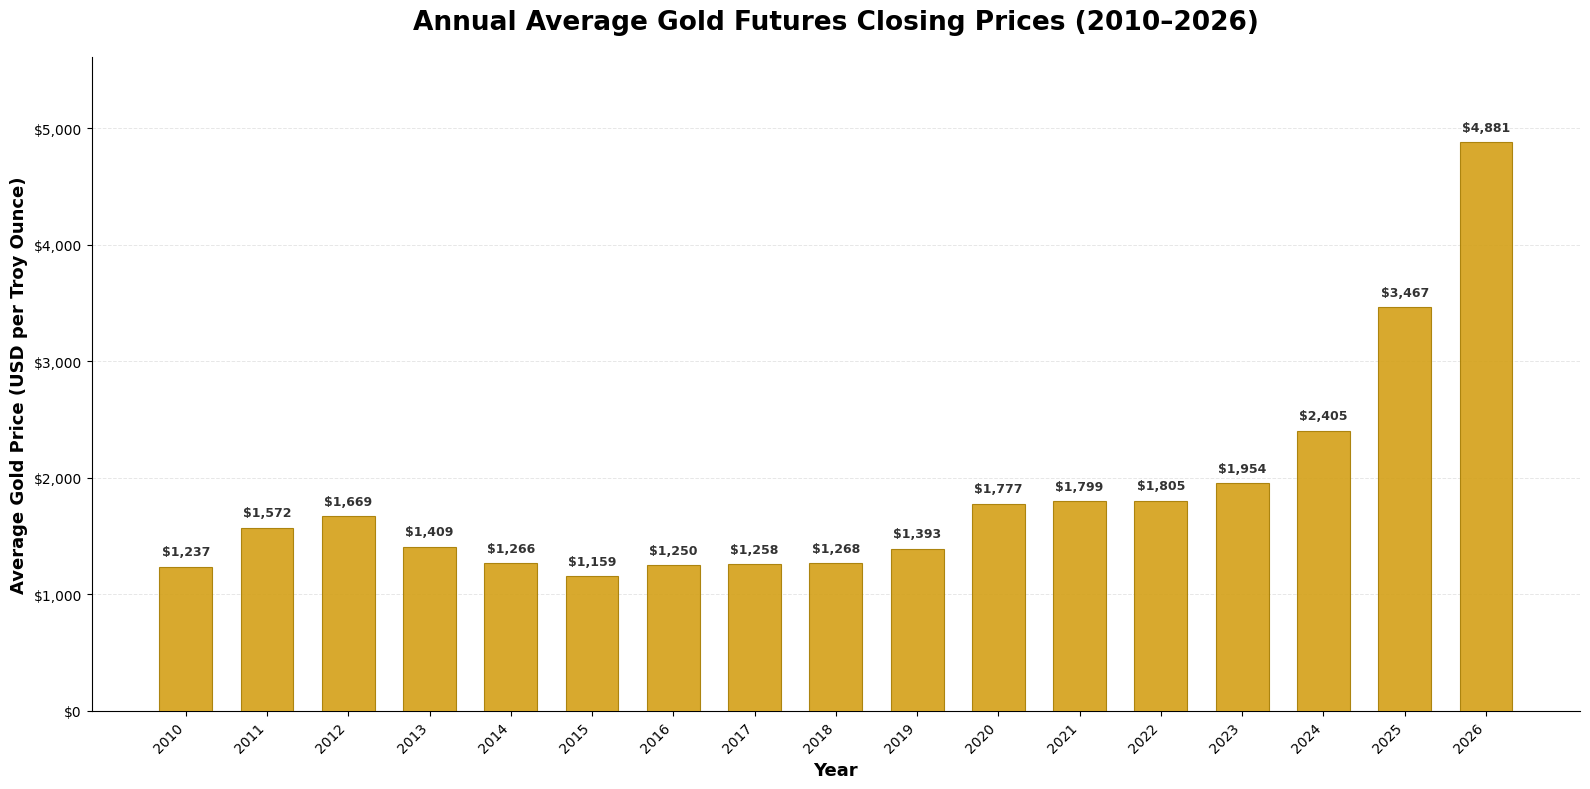

In [14]:

# ANNUAL AVERAGE GOLD PRICES - BAR CHART

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Calculate the average gold closing price for each calendar year
yearly_mean_gold = dataset["Gold"].groupby(
    dataset.index.year
).mean()

# Create a figure with a professional layout
fig, ax = plt.subplots(figsize=(16, 8))

# Create golden bars representing annual average gold prices
bars = ax.bar(
    yearly_mean_gold.index,
    yearly_mean_gold.values,
    color="#D4A017",
    edgecolor="#A67C00",
    linewidth=0.8,
    width=0.65,
    alpha=0.9,
    zorder=3
)

# Display the average gold price above each bar
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"${height:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color="#333333"
    )

# Add a descriptive chart title and axis labels
ax.set_title(
    "Annual Average Gold Futures Closing Prices (2010–2026)",
    fontsize=19,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Year", fontsize=13, fontweight="bold")
ax.set_ylabel(
    "Average Gold Price (USD per Troy Ounce)",
    fontsize=13,
    fontweight="bold"
)

# Display all years on the horizontal axis
ax.set_xticks(yearly_mean_gold.index)
ax.set_xticklabels(
    yearly_mean_gold.index,
    rotation=45,
    ha="right",
    fontsize=10
)

# Format the vertical axis using USD currency labels
ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

# Add subtle horizontal gridlines for readability
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
    zorder=0
)

# Remove unnecessary chart borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add space above the highest bar for price annotations
ax.set_ylim(0, yearly_mean_gold.max() * 1.15)

# Adjust spacing and display the final chart
plt.tight_layout()
plt.show()


Correlation analysis

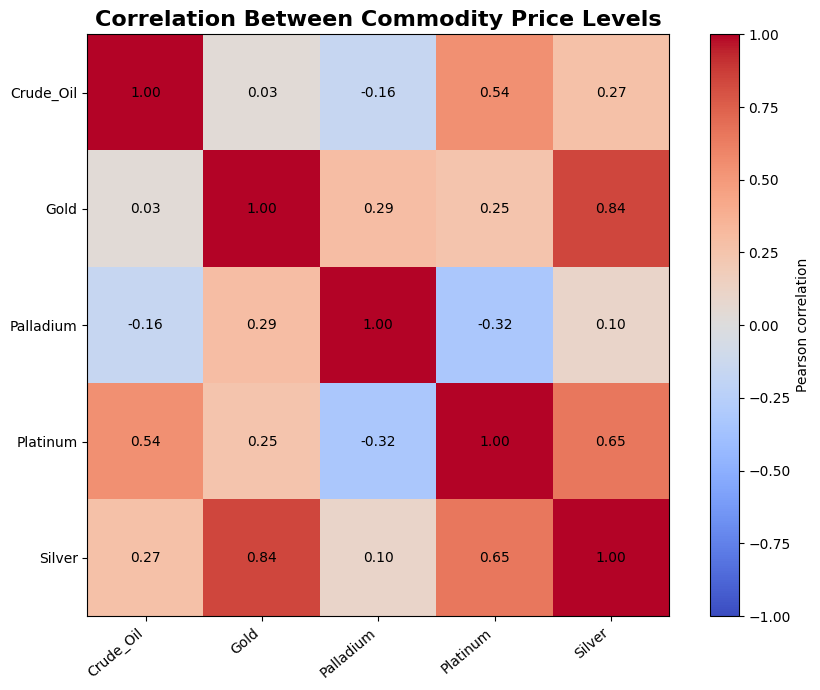

In [15]:
# PRICE CORRELATION

price_corr = dataset.corr()

fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(price_corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(commodities)))
ax.set_xticklabels(commodities, rotation=40, ha="right")
ax.set_yticks(range(len(commodities)))
ax.set_yticklabels(commodities)

for i in range(len(commodities)):
    for j in range(len(commodities)):
        ax.text(
            j, i, f"{price_corr.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=10
        )

ax.set_title("Correlation Between Commodity Price Levels", fontsize=16, fontweight="bold")
fig.colorbar(image, ax=ax, label="Pearson correlation")

plt.tight_layout()
plt.show()

**Analysis:** Gold shows a strong positive correlation with Silver (0.84), weak positive correlations with Palladium (0.29) and Platinum (0.25), and almost no correlation with Crude Oil (0.03). Other notable relationships include Platinum–Silver (0.65), Crude Oil–Platinum (0.54), and a negative correlation between Platinum and Palladium (-0.32). Overall, all five commodities will be retained as potential predictors for further forecasting analysis, with their predictive usefulness evaluated during model development.

Correlation does not prove that another commodity causes gold prices to change or that it will improve forecasting accuracy. That needs to be tested using your forecasting experiments.

Gold price versus other commodities

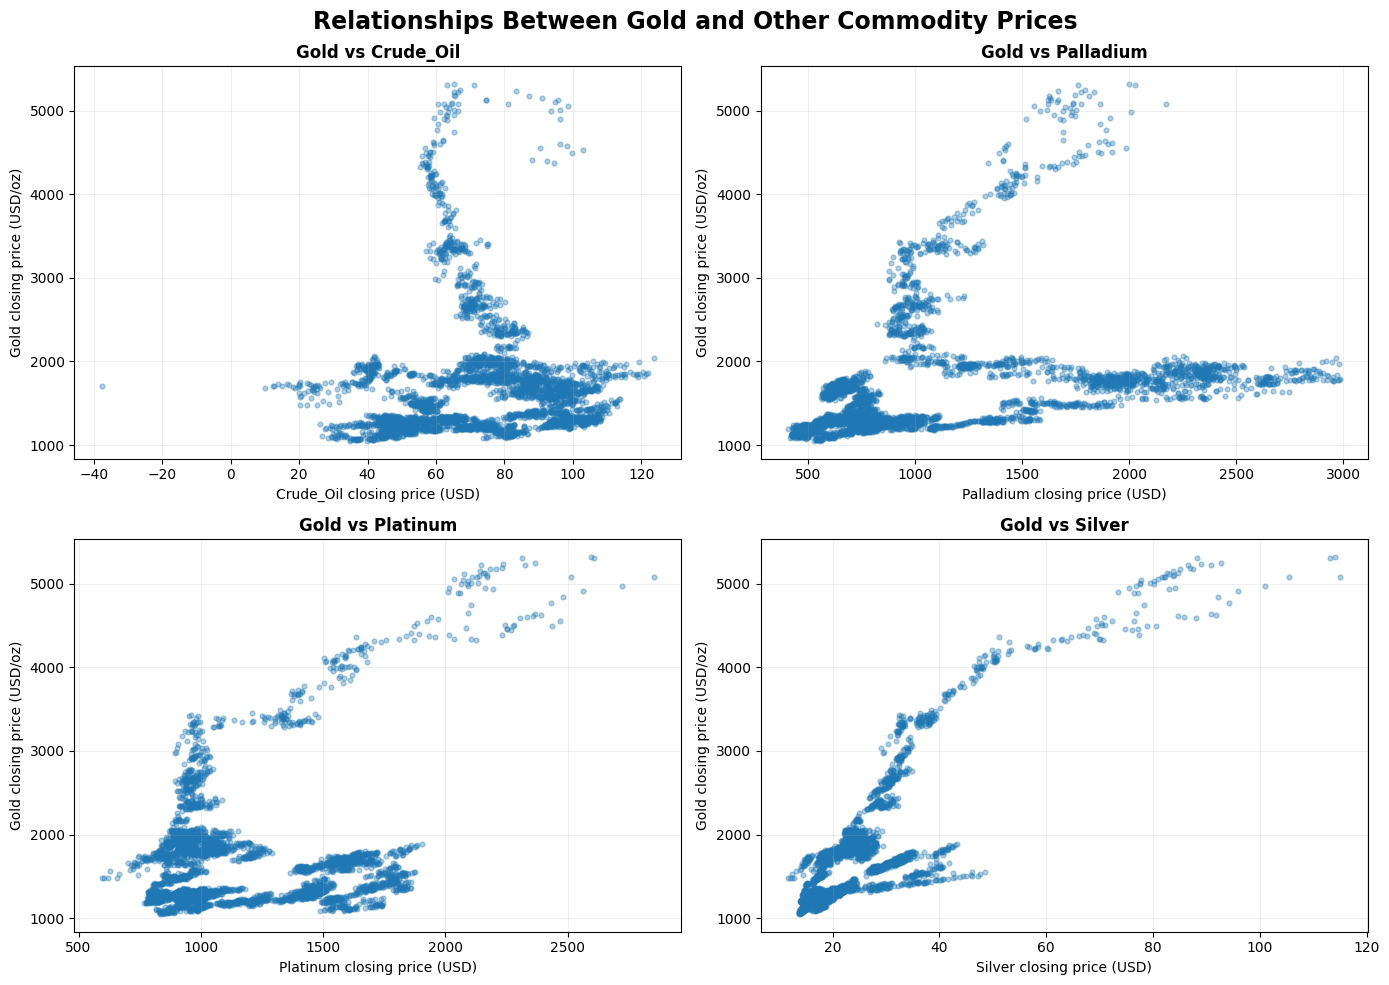

In [16]:
# GOLD VS OTHER COMMODITIES

other_commodities = [c for c in commodities if c != "Gold"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, commodity in zip(axes, other_commodities):
    ax.scatter(
        dataset[commodity],
        dataset["Gold"],
        alpha=0.35,
        s=12
    )

    ax.set_title(f"Gold vs {commodity}", fontweight="bold")
    ax.set_xlabel(f"{commodity} closing price (USD)")
    ax.set_ylabel("Gold closing price (USD/oz)")
    ax.grid(True, alpha=0.2)

plt.suptitle("Relationships Between Gold and Other Commodity Prices", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

**Analysis:** Relationships Between Gold and Other Commodity Prices
- Gold vs Silver: Shows a strong positive relationship, with gold prices generally increasing as silver prices rise.
- Gold vs Palladium: Displays a weak positive relationship with considerable variation.
- Gold vs Platinum: Shows a weak positive relationship with scattered price patterns.
- Gold vs Crude Oil: Shows almost no linear relationship, indicating a very weak correlation.
Overall Conclusion: Silver demonstrates the strongest relationship with gold, while other commodities show weaker and more variable patterns. All four commodities will be retained as candidate predictors, and their forecasting usefulness will be evaluated during model development.

Annual Average trends

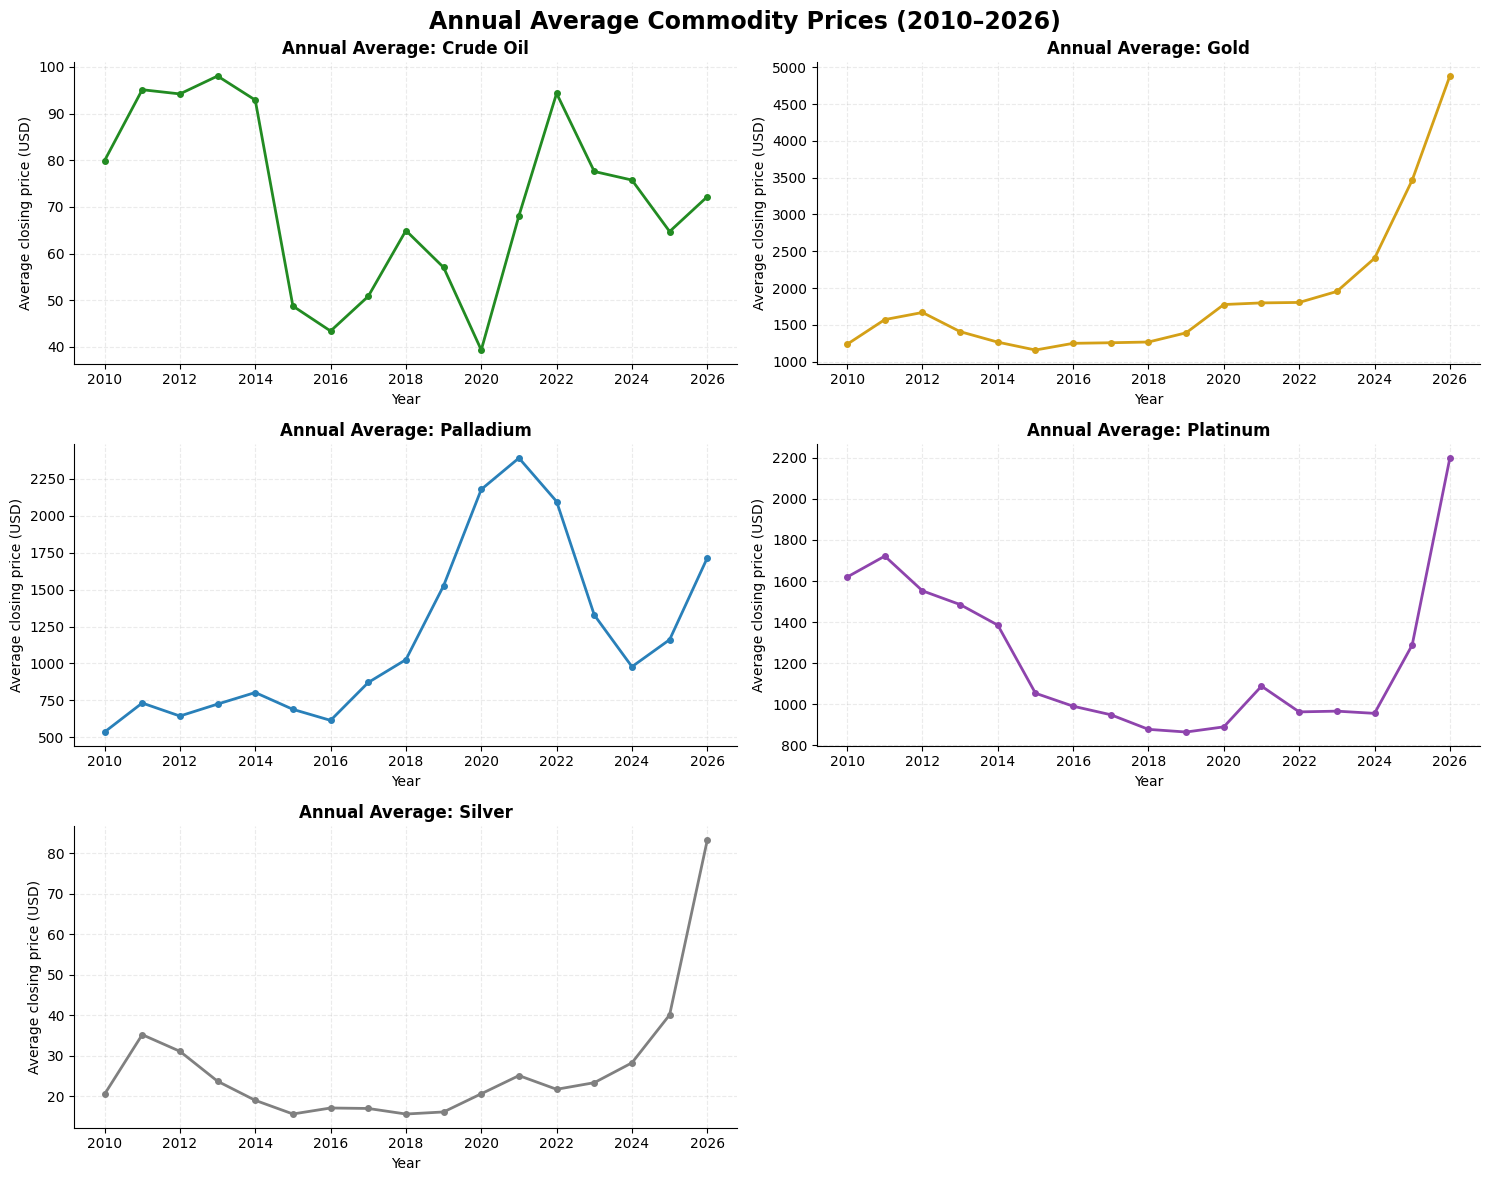

In [17]:
# ANNUAL AVERAGE PRICES

annual_average = dataset.resample("YE").mean()

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for ax, commodity in zip(axes, commodities):
    ax.plot(
        annual_average.index.year,
        annual_average[commodity],
        color=commodity_colors[commodity],
        marker="o",
        markersize=4,
        linewidth=2
    )

    ax.set_title(
        f"Annual Average: {commodity.replace('_', ' ')}",
        fontweight="bold"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Average closing price (USD)")
    ax.grid(True, linestyle="--", alpha=0.25)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].axis("off")

plt.suptitle(
    "Annual Average Commodity Prices (2010–2026)",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Analysis:** Annual Average Commodity Prices (2010–2026)
- Gold: Shows an overall upward trend, with a sharp increase from 2024 to 2026.
- Crude Oil: Exhibits significant fluctuations, including a sharp decline in 2020 followed by recovery.
- Palladium: Increased substantially until 2021, declined through 2024, and recovered during 2025–2026.
- Platinum: Declined from 2011 to 2019 before rising sharply in 2025–2026.
- Silver: Fluctuated over the years before increasing significantly in 2025–2026.
Overall Conclusion: The commodities exhibit different historical price trends and volatility patterns. Gold shows strong long-term growth, while crude oil and palladium experience substantial fluctuations. These findings support retaining all commodities as potential predictors for further forecasting analysis.

Note: The 2026 averages represent January–March observations only, not the complete year.

TIME SERIES FEATURE ENGINEERING

This section creates historical price features and forecasting target for predicting gold prices ahead using machine learning models.

In [18]:
# TIME SERIES FEATURE ENGINEERING

# Use the existing cleaned historical commodity dataset
df = dataset.copy().sort_index()

# Define historical lag periods for all five commodities
lag_periods = [1, 5, 10, 20, 30, 60]

# Create historical lag features for each commodity
for commodity in dataset.columns:
    for lag in lag_periods:
        df[f"{commodity}_lag_{lag}"] = (
            dataset[commodity].shift(lag)
        )

# Calculate historical moving averages of gold prices
for window in [5, 10, 20, 30, 60]:
    df[f"Gold_MA_{window}"] = (
        dataset["Gold"].rolling(window).mean()
    )

# Calculate rolling standard deviation to measure gold price volatility
for window in [5, 10, 20, 30, 60]:
    df[f"Gold_STD_{window}"] = (
        dataset["Gold"].rolling(window).std()
    )

# Calculate gold price momentum over different historical periods
for period in [5, 10, 20, 30]:
    df[f"Gold_Momentum_{period}"] = (
        dataset["Gold"] - dataset["Gold"].shift(period)
    )

# Calculate historical percentage returns of gold prices
for period in [5, 10, 20, 30]:
    df[f"Gold_Return_{period}"] = (
        dataset["Gold"].pct_change(
            periods=period,
            fill_method=None
        )
    )

# Select historical features for gold price prediction
feature_columns = [
    col for col in df.columns
    if col != "Gold"
]

# Remove observations containing missing feature values
df_model = df.dropna().copy()

# Define input features and gold closing price target
X = df_model[feature_columns]
y = df_model["Gold"]

# Retain the latest complete feature row for future forecasting
latest_features = df[feature_columns].dropna().iloc[[-1]]

# Display feature engineering results
print("TIME SERIES FEATURE ENGINEERING COMPLETED")
print("-" * 50)

print("Total observations:", len(df_model))
print("Total input features:", X.shape[1])
print("Target variable:", y.name)
print("Latest feature date:", latest_features.index[-1].date())

# Display the first five observations
display(df_model.head())


TIME SERIES FEATURE ENGINEERING COMPLETED
--------------------------------------------------
Total observations: 4005
Total input features: 52
Target variable: Gold
Latest feature date: 2026-03-30


Ticker,Crude_Oil,Gold,Palladium,Platinum,Silver,Crude_Oil_lag_1,Crude_Oil_lag_5,Crude_Oil_lag_10,Crude_Oil_lag_20,Crude_Oil_lag_30,...,Gold_STD_30,Gold_STD_60,Gold_Momentum_5,Gold_Momentum_10,Gold_Momentum_20,Gold_Momentum_30,Gold_Return_5,Gold_Return_10,Gold_Return_20,Gold_Return_30
Date,,,,,,,,,,,,,,,,,,,,,
2010-04-23,85.120003,1153.099976,562.200012,1740.199951,18.188999,83.699997,83.239998,84.919998,80.529999,82.110001,...,22.825091,20.761112,16.799927,-8.000000,60.400024,45.099976,0.014785,-0.006890,0.055276,0.040704
2010-04-26,84.199997,1153.500000,565.400024,1742.800049,18.334000,85.120003,81.449997,84.339996,80.000000,81.239998,...,22.692466,21.086720,18.300049,-8.099976,49.300049,52.000000,0.016121,-0.006973,0.044648,0.047208
2010-04-27,82.440002,1161.699951,547.950012,1718.699951,18.115999,84.199997,83.449997,84.050003,82.169998,79.800003,...,22.898519,21.575541,23.099976,8.899902,51.399902,56.599976,0.020288,0.007720,0.046294,0.051217
2010-04-28,83.220001,1171.300049,540.900024,1711.400024,18.107000,82.440002,83.680000,85.839996,82.370003,81.699997,...,23.910923,22.362768,23.100098,12.300049,66.800049,49.100098,0.020119,0.010613,0.060480,0.043753
2010-04-29,85.169998,1168.400024,548.000000,1733.699951,18.549000,83.220001,83.699997,85.510002,83.760002,82.930000,...,24.660294,22.977849,26.099976,8.700073,55.099976,44.400024,0.022849,0.007502,0.049492,0.039502


TIME SERIES TRAIN AND TEST SPLIT (80/20)

The dataset is divided chronologically into 80% training and 20% testing to preserve the time series structure. The training dataset is used to develop the machine learning models, while the testing dataset evaluates their performance on unseen historical observations.

In [19]:

# TIME SERIES TRAIN AND TEST SPLIT

# Divide the dataset chronologically into 80% training and 20% testing
split_index = int(len(df_model) * 0.80)

# Select the first 80% of observations for model training
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Select the remaining 20% of observations for model testing
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Display training and testing information
print("TIME SERIES TRAIN AND TEST SPLIT COMPLETED")
print("-" * 50)

print("Total observations:", len(df_model))
print("Total input features:", X.shape[1])

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training period:",
      X_train.index.min().date(), "to",
      X_train.index.max().date())

print("Testing period:",
      X_test.index.min().date(), "to",
      X_test.index.max().date())

print("Missing training values:", X_train.isna().sum().sum())
print("Missing testing values:", X_test.isna().sum().sum())


TIME SERIES TRAIN AND TEST SPLIT COMPLETED
--------------------------------------------------
Total observations: 4005
Total input features: 52
Training observations: 3204
Testing observations: 801
Training period: 2010-04-23 to 2023-01-19
Testing period: 2023-01-20 to 2026-03-30
Missing training values: 0
Missing testing values: 0


# **Model 1: Random Forest Regressor**

The Random Forest Regressor is an ensemble machine learning algorithm that combines multiple decision trees to identify nonlinear relationships between historical commodity prices and future gold prices. The model is trained using historical data and evaluated on unseen testing data.

**Random Forest Model Training**

In [20]:
# RANDOM FOREST MODEL TRAINING
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest regression model
rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=15,
    min_samples_leaf=5,
    random_state=123,
    n_jobs=-1
)

# Train the model using 80% of historical observations
rf_model.fit(X_train, y_train)

# Generate predictions for the training dataset
y_train_pred_rf = rf_model.predict(X_train)

# Generate predictions for the unseen testing dataset
y_pred_rf = rf_model.predict(X_test)

# Display model training information
print("RANDOM FOREST MODEL TRAINING COMPLETED")
print("-" * 50)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total input features:", X_train.shape[1])
print("Number of trees:", rf_model.n_estimators)
print("Maximum tree depth:", rf_model.max_depth)
print("Training predictions:", len(y_train_pred_rf))
print("Testing predictions:", len(y_pred_rf))


RANDOM FOREST MODEL TRAINING COMPLETED
--------------------------------------------------
Training observations: 3204
Testing observations: 801
Total input features: 52
Number of trees: 500
Maximum tree depth: 15
Training predictions: 3204
Testing predictions: 801


Model Evaluation

The Random Forest model is evaluated using the unseen 20% testing dataset. Four regression metrics—RMSE, MAE, R² and MAPE—are calculated to assess prediction accuracy and overall model performance.

In [21]:

# RANDOM FOREST MODEL EVALUATION

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Calculate Root Mean Squared Error (RMSE)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

# Calculate Mean Absolute Error (MAE)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

# Calculate R-squared (R²)
r2_rf = r2_score(y_test, y_pred_rf)

# Calculate Mean Absolute Percentage Error (MAPE)
mape_rf = np.mean(
    np.abs((y_test - y_pred_rf) / y_test)
) * 100

# Display Random Forest evaluation results
print("RANDOM FOREST MODEL EVALUATION")
print("-" * 50)

print(f"RMSE: {rmse_rf:.4f}")
print(f"MAE: {mae_rf:.4f}")
print(f"R² Score: {r2_rf:.4f}")
print(f"MAPE: {mape_rf:.4f}%")


RANDOM FOREST MODEL EVALUATION
--------------------------------------------------
RMSE: 1212.8821
MAE: 828.4972
R² Score: -0.7918
MAPE: 23.4517%


Analysis for your project

The Random Forest model demonstrates poor predictive performance, with a negative R² score of -0.7918 and a high RMSE of 1212.88. The MAPE of 23.45% indicates substantial prediction errors. These results suggest that the model struggles to generalise to unseen historical gold prices, potentially due to significant price increases and changing market conditions.

Actual vs Predicted Gold Prices - Random Forest

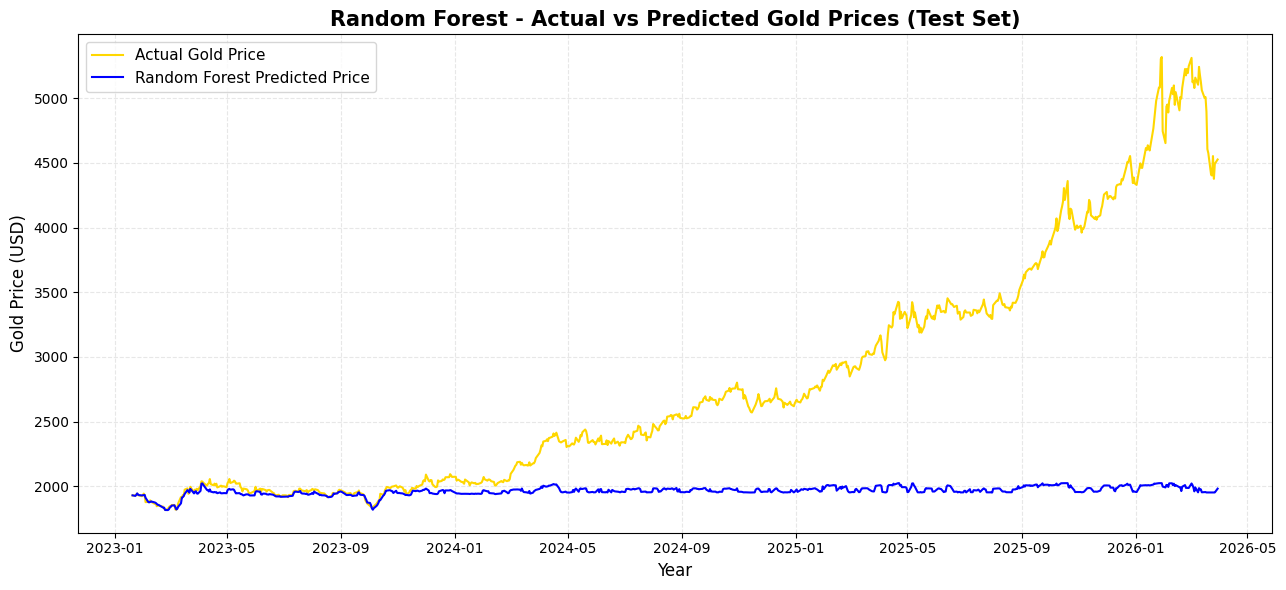

In [22]:
# RANDOM FOREST - ACTUAL VS PREDICTED GOLD PRICES

# Create the figure
plt.figure(figsize=(13, 6))

# Plot actual gold closing prices
plt.plot(
    y_test.index,
    y_test,
    label="Actual Gold Price",
    color="gold"
)

# Plot Random Forest predicted gold prices
plt.plot(
    y_test.index,
    y_pred_rf,
    label="Random Forest Predicted Price",
    color="blue"
)

# Add graph title and axis labels
plt.title(
    "Random Forest - Actual vs Predicted Gold Prices (Test Set)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Improve layout
plt.tight_layout()

# Display the graph
plt.show()


# **Model 2: XGBoost Regressor**
The XGBoost Regressor is a gradient boosting machine learning algorithm that builds decision trees sequentially to minimise prediction errors. It is used to identify complex relationships between historical commodity prices and future gold prices. The model is trained using 80% of the chronological dataset and evaluated on the remaining 20%, with a gap to prevent future target leakage.

In [23]:
# XGBOOST MODEL TRAINING

from xgboost import XGBRegressor

# Initialize the XGBoost regression model
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=123,
    n_jobs=-1
)

# Train XGBoost using 80% of historical observations
xgb_model.fit(X_train, y_train)

# Generate predictions for the training dataset
y_train_pred_xgb = xgb_model.predict(X_train)

# Generate predictions for the unseen testing dataset
y_pred_xgb = xgb_model.predict(X_test)

# Display model training information
print("XGBOOST MODEL TRAINING COMPLETED")
print("-" * 50)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total input features:", X_train.shape[1])
print("Number of estimators:", xgb_model.n_estimators)
print("Learning rate:", xgb_model.learning_rate)
print("Maximum tree depth:", xgb_model.max_depth)
print("Training predictions:", len(y_train_pred_xgb))
print("Testing predictions:", len(y_pred_xgb))


XGBOOST MODEL TRAINING COMPLETED
--------------------------------------------------
Training observations: 3204
Testing observations: 801
Total input features: 52
Number of estimators: 500
Learning rate: 0.05
Maximum tree depth: 6
Training predictions: 3204
Testing predictions: 801


XGBoost Model Evaluation

In [24]:
# Calculate Root Mean Squared Error (RMSE)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

# Calculate Mean Absolute Error (MAE)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

# Calculate R-squared (R²)
r2_xgb = r2_score(y_test, y_pred_xgb)

# Calculate Mean Absolute Percentage Error (MAPE)
mape_xgb = np.mean(
    np.abs((y_test - y_pred_xgb) / y_test)
) * 100

# Display XGBoost evaluation results
print("XGBOOST MODEL EVALUATION")
print("-" * 50)

print(f"RMSE: {rmse_xgb:.4f}")
print(f"MAE: {mae_xgb:.4f}")
print(f"R² Score: {r2_xgb:.4f}")
print(f"MAPE: {mape_xgb:.4f}%")


XGBOOST MODEL EVALUATION
--------------------------------------------------
RMSE: 1213.9328
MAE: 831.0718
R² Score: -0.7949
MAPE: 23.5601%


**Analysis for your project**

The XGBoost model demonstrates poor predictive performance, with an RMSE of 1213.93, MAE of 831.07, R² of -0.7949 and MAPE of 23.56%. Its performance is slightly worse than Random Forest across all four evaluation metrics. The negative R² indicates that both models struggle to generalise to unseen gold prices, potentially due to changing market conditions and strong upward price trends.

XGBoost — Actual vs Predicted Gold Prices (Testing Data)

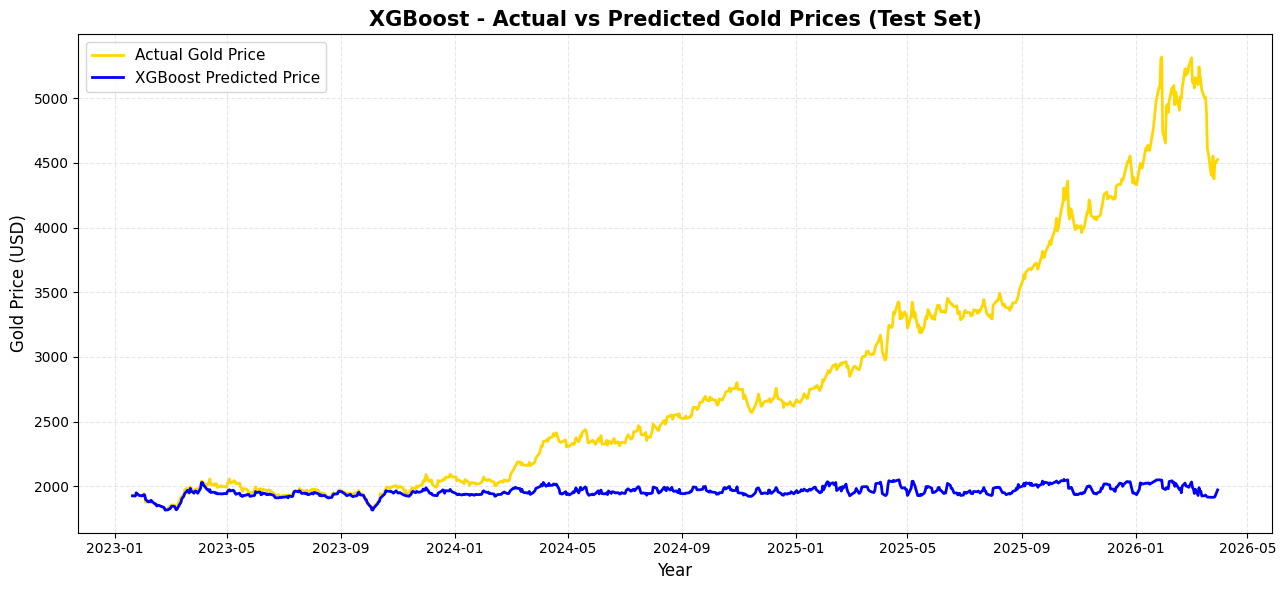

In [25]:
# XGBOOST - ACTUAL VS PREDICTED GOLD PRICES

# Create the figure
plt.figure(figsize=(13, 6))

# Plot actual gold closing prices
plt.plot(
    y_test.index,
    y_test,
    label="Actual Gold Price",
    color="gold",
    linewidth=2
)

# Plot XGBoost predicted gold prices
plt.plot(
    y_test.index,
    y_pred_xgb,
    label="XGBoost Predicted Price",
    color="blue",
    linewidth=2
)

# Add graph title and axis labels
plt.title(
    "XGBoost - Actual vs Predicted Gold Prices (Test Set)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Improve layout
plt.tight_layout()

# Display the graph
plt.show()


### Model Performance Comparison

Both Random Forest and XGBoost were trained using 80% of the historical commodity dataset (2010–2026) and evaluated on the remaining 20% of unseen observations.

| Evaluation Metric | Random Forest | XGBoost |
|---|---:|---:|
| RMSE | 1212.8821 | 1213.9328 |
| MAE | 828.4972 | 831.0718 |
| R² Score | -0.7918 | -0.7949 |
| MAPE | 23.4517% | 23.5601% |

### Analysis

Both models demonstrated poor predictive performance, with negative R² scores and high prediction errors. Random Forest achieved slightly better results than XGBoost across all four evaluation metrics. The negative R² scores indicate that both models performed worse than predicting the test observations using their mean value.

The poor performance may be attributed to significant changes in gold prices during the testing period, particularly the strong upward trend in recent years. As tree-based models, Random Forest and XGBoost can struggle to extrapolate beyond the price ranges observed during training. Consequently, both models may have difficulty capturing substantial increases in gold prices and adapting to changing market conditions.

### Justification for Not Proceeding with Future Forecasting

Based on these evaluation results, neither Random Forest nor XGBoost demonstrated sufficient predictive reliability to justify generating future gold price forecasts. Their high RMSE and MAPE values indicate substantial uncertainty in their predictions, which could increase over longer forecasting horizons.

Therefore, **3-month and 6-month future forecasting will not be performed using these models in their current form**. Instead, the project will proceed with the development and evaluation of an LSTM model to investigate whether a deep learning approach can better capture temporal patterns and changing gold price trends.

This decision ensures that future forecasting is considered only after evaluating model performance rather than relying on predictions from models that have already demonstrated poor generalisation.

**Model 3: LSTM (Long Short-Term Memory)**

LSTM is a recurrent neural network architecture designed to learn patterns and dependencies in sequential data. Unlike Random Forest and XGBoost, LSTM processes sequences of historical observations, making it suitable for investigating temporal relationships in gold prices.

The model uses historical commodity features to predict gold prices approximately three months ahead. The data is scaled using training observations only to prevent information leakage.

**LSTM Data Preparation**

In [26]:
# LSTM DATA PREPARATION

import numpy as np
from sklearn.preprocessing import StandardScaler

# Use the existing engineered commodity dataset
lstm_df = df.copy().sort_index()

# Create next-observation gold closing prices
lstm_df["Gold_Next"] = lstm_df["Gold"].shift(-1)

# Calculate next-observation gold returns
lstm_df["Gold_Next_Return"] = (
    lstm_df["Gold_Next"] / lstm_df["Gold"] - 1
)

# Select all available historical features
lstm_features = ["Gold"] + feature_columns

# Remove observations with missing values
lstm_df = lstm_df.dropna(
    subset=lstm_features + ["Gold_Next_Return", "Gold_Next"]
).copy()

# Set chronological training and testing boundaries
split_index_lstm = int(len(lstm_df) * 0.80)

# Exclude the final training origin to avoid target overlap
train_end_lstm = split_index_lstm - 1

# Define training input features and targets
X_train_raw_lstm = lstm_df[lstm_features].iloc[:train_end_lstm]
y_train_raw_lstm = lstm_df["Gold_Next_Return"].iloc[:train_end_lstm]

# Scale features using training data only
scaler_X_lstm = StandardScaler()
scaler_X_lstm.fit(X_train_raw_lstm)

X_all_scaled_lstm = scaler_X_lstm.transform(
    lstm_df[lstm_features]
)

# Scale target returns using training data only
scaler_y_lstm = StandardScaler()
scaler_y_lstm.fit(
    y_train_raw_lstm.to_numpy().reshape(-1, 1)
)

y_all_scaled_lstm = scaler_y_lstm.transform(
    lstm_df["Gold_Next_Return"].to_numpy().reshape(-1, 1)
).flatten()

print("LSTM DATA PREPARATION COMPLETED")
print("Total observations:", len(lstm_df))
print("Input features:", len(lstm_features))
print("Training observations:", train_end_lstm)
print("Testing observations:", len(lstm_df) - split_index_lstm)


LSTM DATA PREPARATION COMPLETED
Total observations: 4004
Input features: 53
Training observations: 3202
Testing observations: 801


In [27]:
# LSTM SEQUENCE CREATION

# Define historical sequence length
sequence_length = 60

# Create LSTM input sequences and target values
def create_lstm_sequences(features, targets, start, end, length):
    X_seq, y_seq = [], []

    for i in range(max(start, length - 1), end):
        X_seq.append(features[i-length+1:i+1])
        y_seq.append(targets[i])

    return np.array(X_seq), np.array(y_seq)

# Create training sequences
X_train_lstm, y_train_lstm = create_lstm_sequences(
    X_all_scaled_lstm,
    y_all_scaled_lstm,
    0,
    train_end_lstm,
    sequence_length
)

# Create testing sequences
X_test_lstm, y_test_lstm = create_lstm_sequences(
    X_all_scaled_lstm,
    y_all_scaled_lstm,
    split_index_lstm,
    len(lstm_df),
    sequence_length
)

print("LSTM SEQUENCE CREATION COMPLETED")
print("-" * 50)

print("Training sequences:", X_train_lstm.shape)
print("Testing sequences:", X_test_lstm.shape)
print("Training targets:", y_train_lstm.shape)
print("Testing targets:", y_test_lstm.shape)


LSTM SEQUENCE CREATION COMPLETED
--------------------------------------------------
Training sequences: (3143, 60, 53)
Testing sequences: (801, 60, 53)
Training targets: (3143,)
Testing targets: (801,)


**LSTM MODEL ARCHITECTURE AND TRAINING**

The Long Short-Term Memory (LSTM) model is developed to capture temporal relationships and historical patterns in gold prices. The model uses two LSTM layers, dropout regularisation, and a dense output layer to predict gold closing prices.

The model is trained using the historical training sequences, with early stopping to reduce overfitting.

LSTM MODEL - IMPORT LIBRARIES

In [28]:
# LSTM MODEL - IMPORT LIBRARIES
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense

# Set random seeds for reproducibility
np.random.seed(43)
tf.random.set_seed(43)

LSTM Model Architecture

In [29]:
# LSTM MODEL ARCHITECTURE

# Initialize the LSTM model
lstm_model = Sequential()

# Input layer: 60 historical observations and 52 features
lstm_model.add(
    Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]))
)

# First LSTM layer
lstm_model.add(LSTM(50, return_sequences=True))
lstm_model.add(Dropout(0.2, seed=43))

# Second LSTM layer
lstm_model.add(LSTM(50))
lstm_model.add(Dropout(0.2, seed=43))

# Output layer for gold price prediction
lstm_model.add(Dense(1))

# Compile the model
lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model architecture
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        20,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,051 (160.36 KB)

 Trainable params: 41,051 (160.36 KB)

 Non-trainable params: 0 (0.00 B)

LSTM Model Training

In [30]:
# LSTM MODEL TRAINING

# Train the model using historical training sequences
history_lstm = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("LSTM MODEL TRAINING COMPLETED")
print("Epochs completed:", len(history_lstm.history["loss"]))
print("Final training loss:", history_lstm.history["loss"][-1])
print("Final validation loss:", history_lstm.history["val_loss"][-1])


Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 1.0705 - val_loss: 0.8869
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.0415 - val_loss: 1.1077
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0613 - val_loss: 0.9457
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0505 - val_loss: 0.8771
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.0251 - val_loss: 0.8845
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.0166 - val_loss: 0.8782
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.0091 - val_loss: 0.8798
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0104 - val_loss: 0.8961
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.9944 - val_loss: 0.8721
Epoch 10/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.9960 - val_loss: 0.8989
Epoch 11/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.9838 - val_loss: 0.9360
Epoch 12/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.9

LSTM Predictions and Reverse Scaling

In [31]:

# LSTM PREDICTIONS AND REVERSE SCALING

# Generate predicted next-observation gold returns
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)

# Reverse scaling to obtain predicted returns
y_pred_return_lstm = scaler_y_lstm.inverse_transform(
    y_pred_lstm_scaled.reshape(-1, 1)
).flatten()

# Get the latest known gold price for each test observation
gold_current_test = (
    lstm_df["Gold"].iloc[split_index_lstm:].to_numpy()
)

# Convert predicted returns into future gold prices
y_pred_lstm = gold_current_test * (
    1 + y_pred_return_lstm
)

# Extract actual next-observation gold prices
y_test_actual_lstm = (
    lstm_df["Gold_Next"].iloc[split_index_lstm:].to_numpy()
)

print("LSTM PREDICTIONS COMPLETED")
print("-" * 50)

print("Predicted observations:", len(y_pred_lstm))
print("Actual observations:", len(y_test_actual_lstm))


26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
LSTM PREDICTIONS COMPLETED
--------------------------------------------------
Predicted observations: 801
Actual observations: 801


**LSTM Model Evaluation**

The LSTM model is evaluated using the unseen testing dataset to assess its ability to predict future gold prices. Four evaluation metrics are used: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), R² and Mean Absolute Percentage Error (MAPE). The predicted values are converted back to their original USD scale before calculating the evaluation metrics.

In [32]:
# LSTM MODEL EVALUATION
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate evaluation metrics
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual_lstm, y_pred_lstm))
mae_lstm = mean_absolute_error(y_test_actual_lstm, y_pred_lstm)
r2_lstm = r2_score(y_test_actual_lstm, y_pred_lstm)

mape_lstm = np.mean(
    np.abs((y_test_actual_lstm - y_pred_lstm) / y_test_actual_lstm)
) * 100

# Display evaluation results
print("LSTM MODEL EVALUATION")
print("-" * 50)

print(f"RMSE: {rmse_lstm:.4f}")
print(f"MAE: {mae_lstm:.4f}")
print(f"R² Score: {r2_lstm:.4f}")
print(f"MAPE: {mape_lstm:.4f}%")


LSTM MODEL EVALUATION
--------------------------------------------------
RMSE: 47.1034
MAE: 27.0318
R² Score: 0.9973
MAPE: 0.8743%


LSTM — ACTUAL VS PREDICTED GOLD PRICES

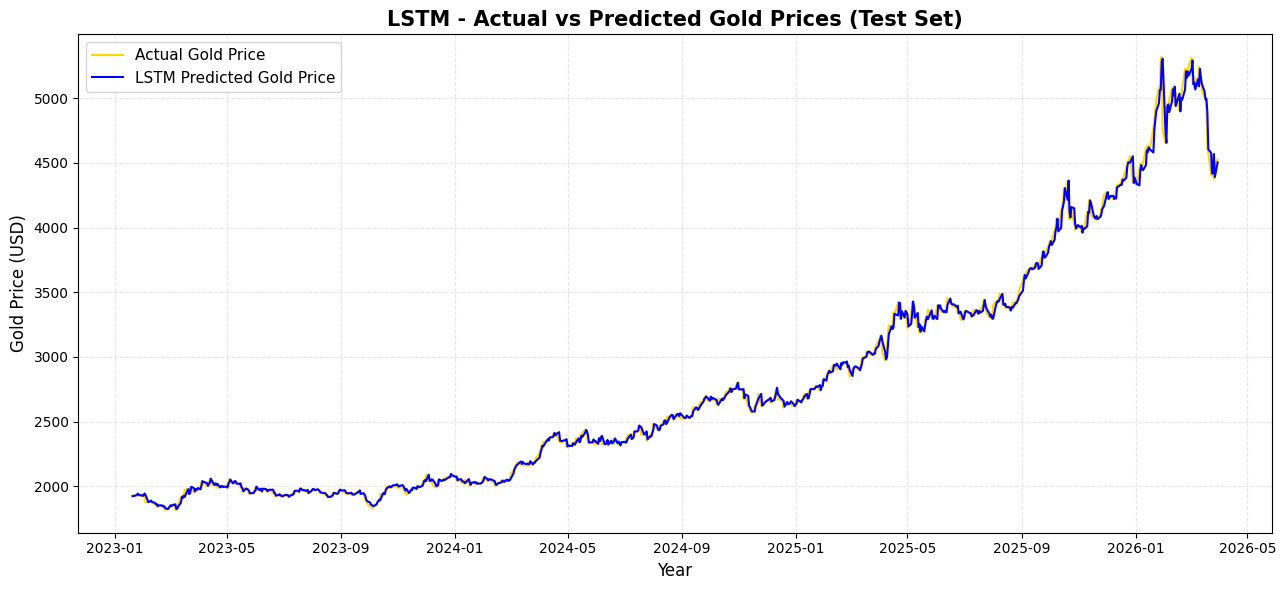

In [33]:

# LSTM - ACTUAL VS PREDICTED GOLD PRICES

import matplotlib.pyplot as plt
import pandas as pd

# Get the actual target dates for next-observation predictions
target_dates = (
    pd.Series(df.index, index=df.index)
    .shift(-1)
    .loc[lstm_df.index[split_index_lstm:]]
    .to_numpy()
)

# Create the figure
plt.figure(figsize=(13, 6))

# Plot actual gold closing prices
plt.plot(
    target_dates,
    y_test_actual_lstm,
    label="Actual Gold Price",
    color="gold"
)

# Plot LSTM predicted gold prices
plt.plot(
    target_dates,
    y_pred_lstm,
    label="LSTM Predicted Gold Price",
    color="blue"
)

# Add graph title and axis labels
plt.title(
    "LSTM - Actual vs Predicted Gold Prices (Test Set)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Improve layout
plt.tight_layout()

# Display the graph
plt.show()


LSTM 3-Month Gold Price Forecasting

In [34]:
# LSTM - 3 MONTH GOLD PRICE FORECASTING

# Define forecast horizon (approximately 3 months)
forecast_days = 63

# Use the complete historical commodity dataset
future_history = dataset.copy().sort_index()

# Retrieve the latest 60 engineered feature observations
latest_sequence = df[lstm_features].dropna().tail(sequence_length)

# Scale the latest input sequence
current_sequence = scaler_X_lstm.transform(latest_sequence)

# Generate future business dates
future_dates = pd.bdate_range(
    start=future_history.index[-1] + pd.Timedelta(days=1),
    periods=forecast_days
)

# Store predicted future gold prices
future_gold_predictions = []

# Generate recursive predictions for 63 business days
for future_date in future_dates:

    # Reshape the sequence for LSTM prediction
    X_future = current_sequence.reshape(
        1, sequence_length, len(lstm_features)
    )

    # Predict the next gold price return
    predicted_scaled_return = lstm_model.predict(
        X_future, verbose=0
    )

    # Convert predicted return to its original scale
    predicted_return = scaler_y_lstm.inverse_transform(
        predicted_scaled_return
    )[0, 0]

    # Retrieve the most recent gold closing price
    last_gold_price = future_history["Gold"].iloc[-1]

    # Calculate the next predicted gold price
    predicted_gold_price = last_gold_price * (
        1 + predicted_return
    )

    # Store the predicted gold price
    future_gold_predictions.append(predicted_gold_price)

    # Update gold with the prediction
    # Keep other commodity prices at their latest observed levels
    next_prices = future_history.iloc[-1].copy()
    next_prices["Gold"] = predicted_gold_price

    future_history.loc[future_date] = next_prices

    # Recalculate historical features for the new observation
    new_features = future_history.iloc[-1].to_dict()

    # Update lag features for all commodities
    for commodity in dataset.columns:
        for lag in [1, 5, 10, 20, 30, 60]:
            new_features[f"{commodity}_lag_{lag}"] = (
                future_history[commodity].iloc[-lag-1]
            )

    # Update gold moving averages and volatility
    for window in [5, 10, 20, 30, 60]:
        gold_window = future_history["Gold"].iloc[-window:]

        new_features[f"Gold_MA_{window}"] = gold_window.mean()
        new_features[f"Gold_STD_{window}"] = gold_window.std()

    # Update gold momentum and historical returns
    for period in [5, 10, 20, 30]:
        past_gold = future_history["Gold"].iloc[-period-1]

        new_features[f"Gold_Momentum_{period}"] = (
            predicted_gold_price - past_gold
        )

        new_features[f"Gold_Return_{period}"] = (
            predicted_gold_price / past_gold - 1
        )

    # Convert updated features into a dataframe
    new_feature_row = pd.DataFrame(
        [new_features],
        columns=lstm_features
    )

    # Scale the new observation
    new_scaled_features = scaler_X_lstm.transform(
        new_feature_row
    )

    # Update the 60-observation sequence
    current_sequence = np.vstack([
        current_sequence[1:],
        new_scaled_features
    ])

# Create a forecast series indexed by future dates
forecast_3m = pd.Series(
    future_gold_predictions,
    index=future_dates,
    name="LSTM Forecast"
)

print("LSTM 3-MONTH FORECAST COMPLETED")
print("-" * 50)
print("Last historical date:", dataset.index[-1].date())
print("Forecast start:", forecast_3m.index[0].date())
print("Forecast end:", forecast_3m.index[-1].date())
print("Forecast observations:", len(forecast_3m))
print(f"Last actual gold price: ${dataset['Gold'].iloc[-1]:,.2f}")
print(f"Final forecast gold price: ${forecast_3m.iloc[-1]:,.2f}")


LSTM 3-MONTH FORECAST COMPLETED
--------------------------------------------------
Last historical date: 2026-03-30
Forecast start: 2026-03-31
Forecast end: 2026-06-25
Forecast observations: 63
Last actual gold price: $4,526.00
Final forecast gold price: $4,355.23


LSTM 3-Month Forecast Graph

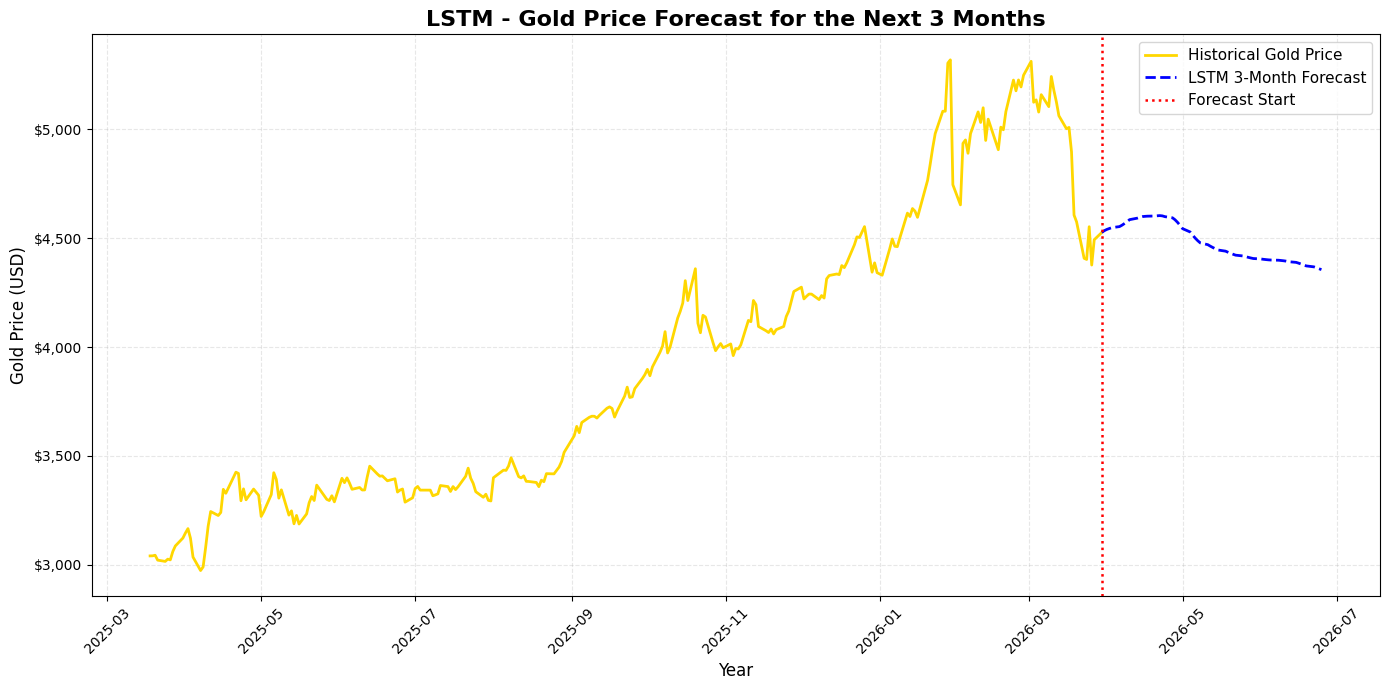

In [35]:

# LSTM - 3 MONTH GOLD PRICE FORECAST GRAPH
import matplotlib.ticker as ticker

# Select the most recent 260 historical observations
historical_gold = dataset["Gold"].iloc[-260:]

# Connect the final actual price to the forecast
forecast_plot_dates = (
    [historical_gold.index[-1]] + list(forecast_3m.index)
)

forecast_plot_prices = (
    [historical_gold.iloc[-1]] + list(forecast_3m.values)
)

# Create the figure
plt.figure(figsize=(14, 7))

# Plot historical gold closing prices
plt.plot(
    historical_gold.index,
    historical_gold.values,
    label="Historical Gold Price",
    color="gold",
    linewidth=2
)

# Plot future gold price predictions
plt.plot(
    forecast_plot_dates,
    forecast_plot_prices,
    label="LSTM 3-Month Forecast",
    color="blue",
    linewidth=2,
    linestyle="--"
)

# Mark the separation between history and forecast
plt.axvline(
    x=historical_gold.index[-1],
    color="red",
    linestyle=":",
    linewidth=1.8,
    label="Forecast Start"
)

# Add graph title and labels
plt.title(
    "LSTM - Gold Price Forecast for the Next 3 Months",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Format gold prices
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Rotate date labels for readability
plt.xticks(rotation=45)

# Improve layout
plt.tight_layout()

# Display the forecast graph
plt.show()


LSTM 6-Month Gold Price Forecasting

In [36]:
# LSTM - 6 MONTH GOLD PRICE FORECASTING

# Extend the existing 3-month forecast to approximately 6 months
additional_days = 63

# Continue from the completed 3-month forecast
future_history_6m = future_history.copy()
current_sequence_6m = current_sequence.copy()

# Generate the additional future business dates
additional_dates = pd.bdate_range(
    start=forecast_3m.index[-1] + pd.Timedelta(days=1),
    periods=additional_days
)

# Store the additional predicted gold prices
additional_predictions = []

# Generate recursive forecasts for the remaining 63 business days
for future_date in additional_dates:

    # Prepare the latest sequence for LSTM prediction
    X_future = current_sequence_6m.reshape(
        1, sequence_length, len(lstm_features)
    )

    # Predict the next gold return
    predicted_scaled_return = lstm_model.predict(
        X_future, verbose=0
    )

    # Reverse scaling
    predicted_return = scaler_y_lstm.inverse_transform(
        predicted_scaled_return
    )[0, 0]

    # Calculate the next predicted gold price
    last_gold_price = future_history_6m["Gold"].iloc[-1]

    predicted_gold_price = last_gold_price * (
        1 + predicted_return
    )

    additional_predictions.append(predicted_gold_price)

    # Update gold price while holding other commodities constant
    next_prices = future_history_6m.iloc[-1].copy()
    next_prices["Gold"] = predicted_gold_price

    future_history_6m.loc[future_date] = next_prices

    # Update historical features
    new_features = future_history_6m.iloc[-1].to_dict()

    # Update commodity lag features
    for commodity in dataset.columns:
        for lag in [1, 5, 10, 20, 30, 60]:
            new_features[f"{commodity}_lag_{lag}"] = (
                future_history_6m[commodity].iloc[-lag-1]
            )

    # Update gold moving averages and volatility
    for window in [5, 10, 20, 30, 60]:
        gold_window = future_history_6m["Gold"].iloc[-window:]

        new_features[f"Gold_MA_{window}"] = gold_window.mean()
        new_features[f"Gold_STD_{window}"] = gold_window.std()

    # Update gold momentum and historical returns
    for period in [5, 10, 20, 30]:
        past_gold = future_history_6m["Gold"].iloc[-period-1]

        new_features[f"Gold_Momentum_{period}"] = (
            predicted_gold_price - past_gold
        )

        new_features[f"Gold_Return_{period}"] = (
            predicted_gold_price / past_gold - 1
        )

    # Scale newly generated features
    new_feature_row = pd.DataFrame(
        [new_features],
        columns=lstm_features
    )

    new_scaled_features = scaler_X_lstm.transform(
        new_feature_row
    )

    # Update the input sequence
    current_sequence_6m = np.vstack([
        current_sequence_6m[1:],
        new_scaled_features
    ])

# Combine the existing 3-month forecast with the extension
forecast_6m = pd.concat([
    forecast_3m,
    pd.Series(additional_predictions, index=additional_dates)
])

forecast_6m.name = "LSTM 6-Month Forecast"

# Display forecasting results
print("LSTM 6-MONTH FORECAST COMPLETED")
print("-" * 50)

print("Forecast start:", forecast_6m.index[0].date())
print("Forecast end:", forecast_6m.index[-1].date())
print("Forecast observations:", len(forecast_6m))

print(f"Last actual gold price: ${dataset['Gold'].iloc[-1]:,.2f}")
print(f"Final forecast gold price: ${forecast_6m.iloc[-1]:,.2f}")


LSTM 6-MONTH FORECAST COMPLETED
--------------------------------------------------
Forecast start: 2026-03-31
Forecast end: 2026-09-22
Forecast observations: 126
Last actual gold price: $4,526.00
Final forecast gold price: $4,143.46


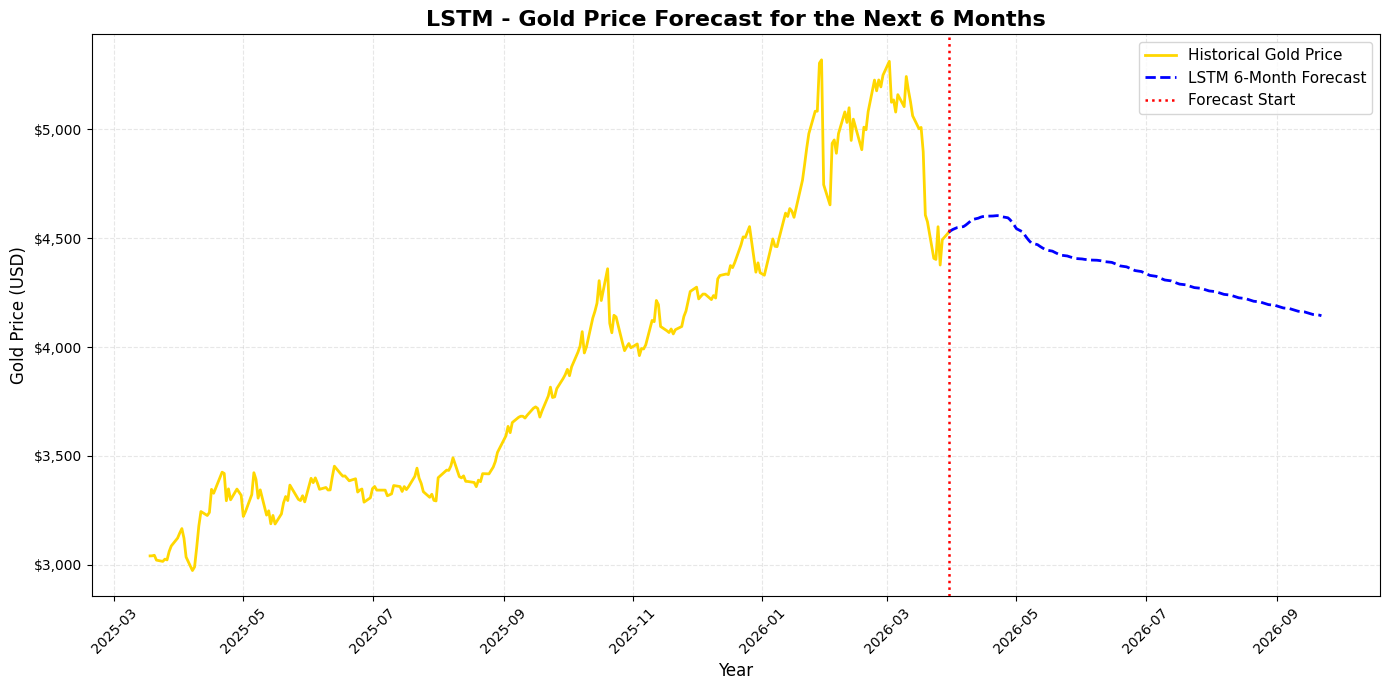

In [38]:
# LSTM - 6 MONTH GOLD PRICE FORECAST GRAPH

# Select the most recent 260 historical observations
historical_gold = dataset["Gold"].iloc[-260:]

# Connect the final actual gold price to the forecast
forecast_plot_dates_6m = (
    [historical_gold.index[-1]] + list(forecast_6m.index)
)

forecast_plot_prices_6m = (
    [historical_gold.iloc[-1]] + list(forecast_6m.values)
)

# Create the figure
plt.figure(figsize=(14, 7))

# Plot historical gold prices
plt.plot(
    historical_gold.index,
    historical_gold.values,
    label="Historical Gold Price",
    color="gold",
    linewidth=2
)

# Plot the 6-month LSTM forecast
plt.plot(
    forecast_plot_dates_6m,
    forecast_plot_prices_6m,
    label="LSTM 6-Month Forecast",
    color="blue",
    linewidth=2,
    linestyle="--"
)

# Mark the start of forecasting
plt.axvline(
    x=historical_gold.index[-1],
    color="red",
    linestyle=":",
    linewidth=1.8,
    label="Forecast Start"
)

# Add graph title and labels
plt.title(
    "LSTM - Gold Price Forecast for the Next 6 Months",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Format gold prices in USD
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Rotate date labels for readability
plt.xticks(rotation=45)

# Improve layout
plt.tight_layout()

# Display the forecast graph
plt.show()


**Model 4: GRU (Gated Recurrent Unit )**

The Gated Recurrent Unit (GRU) model is developed to capture temporal relationships and historical patterns in gold prices. GRU is a recurrent neural network architecture that uses gating mechanisms to learn sequential dependencies while requiring fewer parameters than LSTM.

GRU Model: Import Libraries

In [55]:
# GRU MODEL - IMPORT LIBRARIES
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dropout, Dense



**GRU Model Architecture**

The GRU architecture consists of two hidden layers with 50 units each. Dropout regularisation is applied after each GRU layer to reduce overfitting, while the final dense layer produces a single predicted gold price return for the next observation.

In [56]:
# GRU MODEL ARCHITECTURE

# Initialize the GRU model
gru_model = Sequential()

# Define input shape using 60 historical observations and 53 features
gru_model.add(
    Input(shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]))
)

# First GRU layer
gru_model.add(GRU(50, return_sequences=True))
gru_model.add(Dropout(0.2, seed=43))

# Second GRU layer
gru_model.add(GRU(50))
gru_model.add(Dropout(0.2, seed=43))

# Output layer for next-observation gold return prediction
gru_model.add(Dense(1))

# Compile the model
gru_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model architecture
gru_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 60, 50)         │        15,750 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 50)             │        15,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,101 (121.49 KB)

 Trainable params: 31,101 (121.49 KB)

 Non-trainable params: 0 (0.00 B)

GRU Model Training

The GRU model is trained on the historical training sequences using 20 epochs and a batch size of 32. A chronological validation split of 10% is used to monitor model performance during training. Data shuffling is disabled to preserve the time series order.

In [57]:
# GRU MODEL TRAINING

# Train the GRU model using historical training sequences
history_gru = gru_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

# Display training information
print("GRU MODEL TRAINING COMPLETED")
print("-" * 50)

print("Training sequences:", len(X_train_lstm))
print("Testing sequences:", len(X_test_lstm))
print("Epochs completed:", len(history_gru.history["loss"]))
print("Final training loss:", history_gru.history["loss"][-1])
print("Final validation loss:", history_gru.history["val_loss"][-1])


Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 1.1497 - val_loss: 0.9259
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0574 - val_loss: 0.8901
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.1340 - val_loss: 1.0537
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0415 - val_loss: 0.9413
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.0435 - val_loss: 0.9549
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.0325 - val_loss: 0.9248
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.0289 - val_loss: 0.9097
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0146 - val_loss: 0.9189
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0211 - val_loss: 0.9163
Epoch 10/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0116 - val_loss: 0.9175
Epoch 11/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0073 - val_loss: 0.9188
Epoch 12/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.0

GRU PREDICTIONS AND REVERSE SCALING

After training the GRU model, predictions are generated using the unseen 20% testing dataset. The predicted values are converted from scaled returns into their original form and then used to calculate gold closing prices in USD.

This ensures that GRU and LSTM are evaluated using the same next-observation forecasting approach.

In [58]:
# GRU PREDICTIONS AND REVERSE SCALING

# Predict gold price returns using the unseen testing dataset
y_pred_gru_scaled = gru_model.predict(X_test_lstm)

# Reverse scaling to obtain predicted gold returns
y_pred_return_gru = scaler_y_lstm.inverse_transform(
    y_pred_gru_scaled.reshape(-1, 1)
).flatten()

# Retrieve the latest known gold price for each test observation
gold_current_test_gru = (
    lstm_df["Gold"].iloc[split_index_lstm:].to_numpy()
)

# Convert predicted returns into gold closing prices
y_pred_gru = gold_current_test_gru * (
    1 + y_pred_return_gru
)

# Extract actual next-observation gold closing prices
y_test_actual_gru = (
    lstm_df["Gold_Next"].iloc[split_index_lstm:].to_numpy()
)

# Display prediction information
print("GRU PREDICTIONS COMPLETED")
print("-" * 50)

print("Predicted observations:", len(y_pred_gru))
print("Actual observations:", len(y_test_actual_gru))


26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
GRU PREDICTIONS COMPLETED
--------------------------------------------------
Predicted observations: 801
Actual observations: 801


GRU MODEL EVALUATION

In [59]:
# GRU MODEL EVALUATION
# Calculate Root Mean Squared Error (RMSE)
rmse_gru = np.sqrt(
    mean_squared_error(y_test_actual_gru, y_pred_gru)
)

# Calculate Mean Absolute Error (MAE)
mae_gru = mean_absolute_error(
    y_test_actual_gru, y_pred_gru
)

# Calculate R-squared (R²)
r2_gru = r2_score(
    y_test_actual_gru, y_pred_gru
)

# Calculate Mean Absolute Percentage Error (MAPE)
mape_gru = np.mean(
    np.abs(
        (y_test_actual_gru - y_pred_gru) / y_test_actual_gru
    )
) * 100

# Display GRU evaluation results
print("GRU MODEL EVALUATION")
print("-" * 50)

print(f"RMSE: {rmse_gru:.4f}")
print(f"MAE: {mae_gru:.4f}")
print(f"R² Score: {r2_gru:.4f}")
print(f"MAPE: {mape_gru:.4f}%")


GRU MODEL EVALUATION
--------------------------------------------------
RMSE: 53.2447
MAE: 33.4264
R² Score: 0.9965
MAPE: 1.0605%


GRU — ACTUAL VS PREDICTED GOLD PRICES

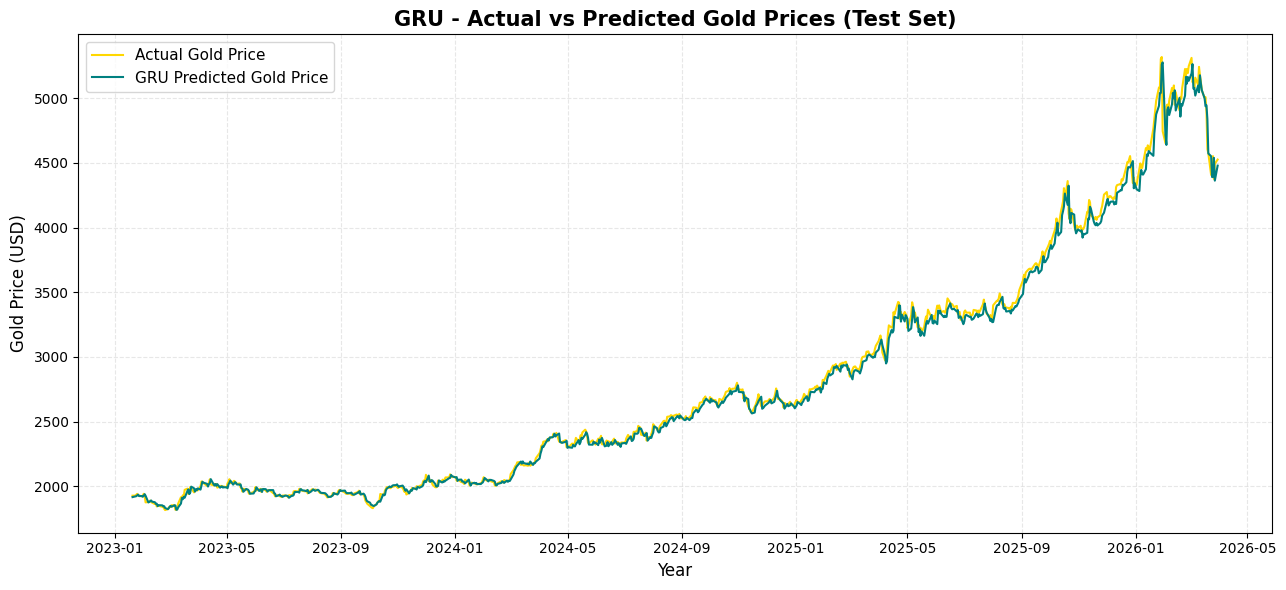

In [60]:
# GRU - ACTUAL VS PREDICTED GOLD PRICES

# Get the actual target dates for next-observation predictions
target_dates_gru = (
    pd.Series(df.index, index=df.index)
    .shift(-1)
    .loc[lstm_df.index[split_index_lstm:]]
    .to_numpy()
)

# Create the figure
plt.figure(figsize=(13, 6))

# Plot actual gold closing prices
plt.plot(
    target_dates_gru,
    y_test_actual_gru,
    label="Actual Gold Price",
    color="gold"
)

# Plot GRU predicted gold prices
plt.plot(
    target_dates_gru,
    y_pred_gru,
    label="GRU Predicted Gold Price",
    color="teal"
)

# Add graph title and axis labels
plt.title(
    "GRU - Actual vs Predicted Gold Prices (Test Set)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Improve layout
plt.tight_layout()

# Display the graph
plt.show()


GRU — 3-Month Gold Price Forecasting

The trained GRU model used to generate gold price forecasts for approximately 3 months (63 business days) beyond 30 March 2026.

The GRU model predicts the next-observation gold price return. These predictions are recursively converted into future gold prices, while the latest available prices of other commodities are held constant.

In [61]:
# GRU - 3 MONTH GOLD PRICE FORECASTING

# Define forecast horizon (approximately 3 months)
forecast_days_gru = 63

# Use the complete historical commodity dataset
future_history_gru = dataset.copy().sort_index()

# Retrieve the latest 60 engineered feature observations
latest_sequence_gru = df[lstm_features].dropna().tail(sequence_length)

# Scale the latest input sequence
current_sequence_gru = scaler_X_lstm.transform(latest_sequence_gru)

# Generate future business dates
future_dates_gru = pd.bdate_range(
    start=future_history_gru.index[-1] + pd.Timedelta(days=1),
    periods=forecast_days_gru
)

# Store predicted future gold prices
future_gold_predictions_gru = []

# Generate recursive predictions for 63 business days
for future_date in future_dates_gru:

    # Reshape the sequence for GRU prediction
    X_future_gru = current_sequence_gru.reshape(
        1, sequence_length, len(lstm_features)
    )

    # Predict the next gold price return
    predicted_scaled_return_gru = gru_model.predict(
        X_future_gru, verbose=0
    )

    # Reverse scaling to obtain the predicted return
    predicted_return_gru = scaler_y_lstm.inverse_transform(
        predicted_scaled_return_gru
    )[0, 0]

    # Retrieve the latest gold closing price
    last_gold_price_gru = future_history_gru["Gold"].iloc[-1]

    # Calculate the next predicted gold price
    predicted_gold_price_gru = last_gold_price_gru * (
        1 + predicted_return_gru
    )

    # Store the predicted gold price
    future_gold_predictions_gru.append(predicted_gold_price_gru)

    # Update gold while keeping other commodity prices constant
    next_prices_gru = future_history_gru.iloc[-1].copy()
    next_prices_gru["Gold"] = predicted_gold_price_gru

    future_history_gru.loc[future_date] = next_prices_gru

    # Recalculate the historical features
    new_features_gru = future_history_gru.iloc[-1].to_dict()

    # Update commodity lag features
    for commodity in dataset.columns:
        for lag in [1, 5, 10, 20, 30, 60]:
            new_features_gru[f"{commodity}_lag_{lag}"] = (
                future_history_gru[commodity].iloc[-lag-1]
            )

    # Update gold moving averages and volatility
    for window in [5, 10, 20, 30, 60]:
        gold_window_gru = future_history_gru["Gold"].iloc[-window:]

        new_features_gru[f"Gold_MA_{window}"] = gold_window_gru.mean()
        new_features_gru[f"Gold_STD_{window}"] = gold_window_gru.std()

    # Update gold momentum and historical returns
    for period in [5, 10, 20, 30]:
        past_gold_gru = future_history_gru["Gold"].iloc[-period-1]

        new_features_gru[f"Gold_Momentum_{period}"] = (
            predicted_gold_price_gru - past_gold_gru
        )

        new_features_gru[f"Gold_Return_{period}"] = (
            predicted_gold_price_gru / past_gold_gru - 1
        )

    # Convert updated features into a dataframe
    new_feature_row_gru = pd.DataFrame(
        [new_features_gru],
        columns=lstm_features
    )

    # Scale the new observation
    new_scaled_features_gru = scaler_X_lstm.transform(
        new_feature_row_gru
    )

    # Update the 60-observation input sequence
    current_sequence_gru = np.vstack([
        current_sequence_gru[1:],
        new_scaled_features_gru
    ])

# Create the forecast series
forecast_3m_gru = pd.Series(
    future_gold_predictions_gru,
    index=future_dates_gru,
    name="GRU 3-Month Forecast"
)

# Display forecast information
print("GRU 3-MONTH FORECAST COMPLETED")
print("-" * 50)

print("Last historical date:", dataset.index[-1].date())
print("Forecast start:", forecast_3m_gru.index[0].date())
print("Forecast end:", forecast_3m_gru.index[-1].date())
print("Forecast observations:", len(forecast_3m_gru))

print(f"Last actual gold price: ${dataset['Gold'].iloc[-1]:,.2f}")
print(f"Final forecast gold price: ${forecast_3m_gru.iloc[-1]:,.2f}")


GRU 3-MONTH FORECAST COMPLETED
--------------------------------------------------
Last historical date: 2026-03-30
Forecast start: 2026-03-31
Forecast end: 2026-06-25
Forecast observations: 63
Last actual gold price: $4,526.00
Final forecast gold price: $3,083.04


GRU 3-Month Forecast Graph

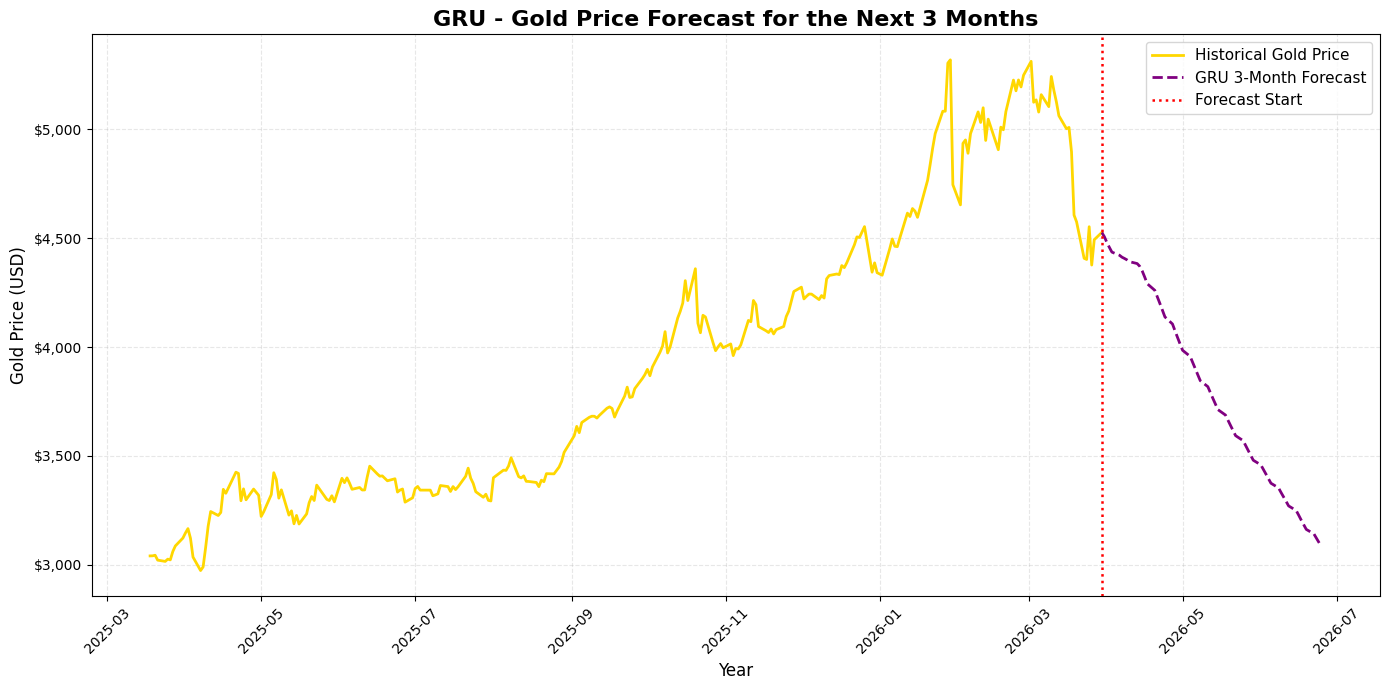

In [62]:
# GRU - 3 MONTH GOLD PRICE FORECAST GRAPH

# Select the most recent 260 historical observations
historical_gold_gru = dataset["Gold"].iloc[-260:]

# Connect the final actual gold price to the forecast
forecast_plot_dates_gru = (
    [historical_gold_gru.index[-1]] + list(forecast_3m_gru.index)
)

forecast_plot_prices_gru = (
    [historical_gold_gru.iloc[-1]] + list(forecast_3m_gru.values)
)

# Create the figure
plt.figure(figsize=(14, 7))

# Plot historical gold closing prices
plt.plot(
    historical_gold_gru.index,
    historical_gold_gru.values,
    label="Historical Gold Price",
    color="gold",
    linewidth=2
)

# Plot the GRU 3-month forecast
plt.plot(
    forecast_plot_dates_gru,
    forecast_plot_prices_gru,
    label="GRU 3-Month Forecast",
    color="purple",
    linewidth=2,
    linestyle="--"
)

# Mark the start of future forecasting
plt.axvline(
    x=historical_gold_gru.index[-1],
    color="red",
    linestyle=":",
    linewidth=1.8,
    label="Forecast Start"
)

# Add graph title and axis labels
plt.title(
    "GRU - Gold Price Forecast for the Next 3 Months",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Format gold prices in USD
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Rotate date labels for readability
plt.xticks(rotation=45)

# Improve layout
plt.tight_layout()

# Display the forecast graph
plt.show()


GRU — 6-Month Gold Price Forecasting

The trained GRU model is used to extend the existing 3-month gold price forecast to approximately 6 months (126 business days), covering April–September 2026.

Future gold price returns are predicted recursively and converted into closing prices in USD. The forecasting process continues from the existing 3-month predictions without retraining the model.

In [63]:
# GRU - 6 MONTH GOLD PRICE FORECASTING

# Extend the existing 3-month forecast by another 63 business days
additional_days_gru = 63

# Continue from the completed 3-month GRU forecast
future_history_6m_gru = future_history_gru.copy()
current_sequence_6m_gru = current_sequence_gru.copy()

# Generate additional future business dates
additional_dates_gru = pd.bdate_range(
    start=forecast_3m_gru.index[-1] + pd.Timedelta(days=1),
    periods=additional_days_gru
)

# Store the additional predicted gold prices
additional_predictions_gru = []

# Generate recursive forecasts for the remaining 63 business days
for future_date in additional_dates_gru:

    # Prepare the latest sequence for GRU prediction
    X_future_gru = current_sequence_6m_gru.reshape(
        1, sequence_length, len(lstm_features)
    )

    # Predict the next gold price return
    predicted_scaled_return_gru = gru_model.predict(
        X_future_gru,
        verbose=0
    )

    # Reverse scaling to obtain the predicted return
    predicted_return_gru = scaler_y_lstm.inverse_transform(
        predicted_scaled_return_gru
    )[0, 0]

    # Retrieve the latest gold closing price
    last_gold_price_gru = future_history_6m_gru["Gold"].iloc[-1]

    # Calculate the next predicted gold price
    predicted_gold_price_gru = last_gold_price_gru * (
        1 + predicted_return_gru
    )

    # Store the predicted gold price
    additional_predictions_gru.append(predicted_gold_price_gru)

    # Update gold while keeping other commodity prices constant
    next_prices_gru = future_history_6m_gru.iloc[-1].copy()
    next_prices_gru["Gold"] = predicted_gold_price_gru

    future_history_6m_gru.loc[future_date] = next_prices_gru

    # Update commodity lag features
    new_features_gru = future_history_6m_gru.iloc[-1].to_dict()

    for commodity in dataset.columns:
        for lag in [1, 5, 10, 20, 30, 60]:
            new_features_gru[f"{commodity}_lag_{lag}"] = (
                future_history_6m_gru[commodity].iloc[-lag-1]
            )

    # Update gold moving averages and volatility
    for window in [5, 10, 20, 30, 60]:
        gold_window_gru = future_history_6m_gru["Gold"].iloc[-window:]

        new_features_gru[f"Gold_MA_{window}"] = gold_window_gru.mean()
        new_features_gru[f"Gold_STD_{window}"] = gold_window_gru.std()

    # Update gold momentum and historical returns
    for period in [5, 10, 20, 30]:
        past_gold_gru = future_history_6m_gru["Gold"].iloc[-period-1]

        new_features_gru[f"Gold_Momentum_{period}"] = (
            predicted_gold_price_gru - past_gold_gru
        )

        new_features_gru[f"Gold_Return_{period}"] = (
            predicted_gold_price_gru / past_gold_gru - 1
        )

    # Convert updated features into a dataframe
    new_feature_row_gru = pd.DataFrame(
        [new_features_gru],
        columns=lstm_features
    )

    # Scale the new observation
    new_scaled_features_gru = scaler_X_lstm.transform(
        new_feature_row_gru
    )

    # Update the input sequence
    current_sequence_6m_gru = np.vstack([
        current_sequence_6m_gru[1:],
        new_scaled_features_gru
    ])

# Combine the existing 3-month forecast with the extension
forecast_6m_gru = pd.concat([
    forecast_3m_gru,
    pd.Series(
        additional_predictions_gru,
        index=additional_dates_gru
    )
])

forecast_6m_gru.name = "GRU 6-Month Forecast"

# Display forecast information
print("GRU 6-MONTH FORECAST COMPLETED")
print("-" * 50)

print("Forecast start:", forecast_6m_gru.index[0].date())
print("Forecast end:", forecast_6m_gru.index[-1].date())
print("Forecast observations:", len(forecast_6m_gru))

print(f"Last actual gold price: ${dataset['Gold'].iloc[-1]:,.2f}")
print(f"Final forecast gold price: ${forecast_6m_gru.iloc[-1]:,.2f}")


GRU 6-MONTH FORECAST COMPLETED
--------------------------------------------------
Forecast start: 2026-03-31
Forecast end: 2026-09-22
Forecast observations: 126
Last actual gold price: $4,526.00
Final forecast gold price: $2,076.84


GRU — 6-Month Gold Price Forecast Graph

The graph illustrates historical gold closing prices alongside the GRU model's projected prices for approximately six months (April–September 2026). Historical prices are displayed in gold, while forecasted prices are represented by a purple dashed line. A red vertical line indicates the beginning of the forecasting period.


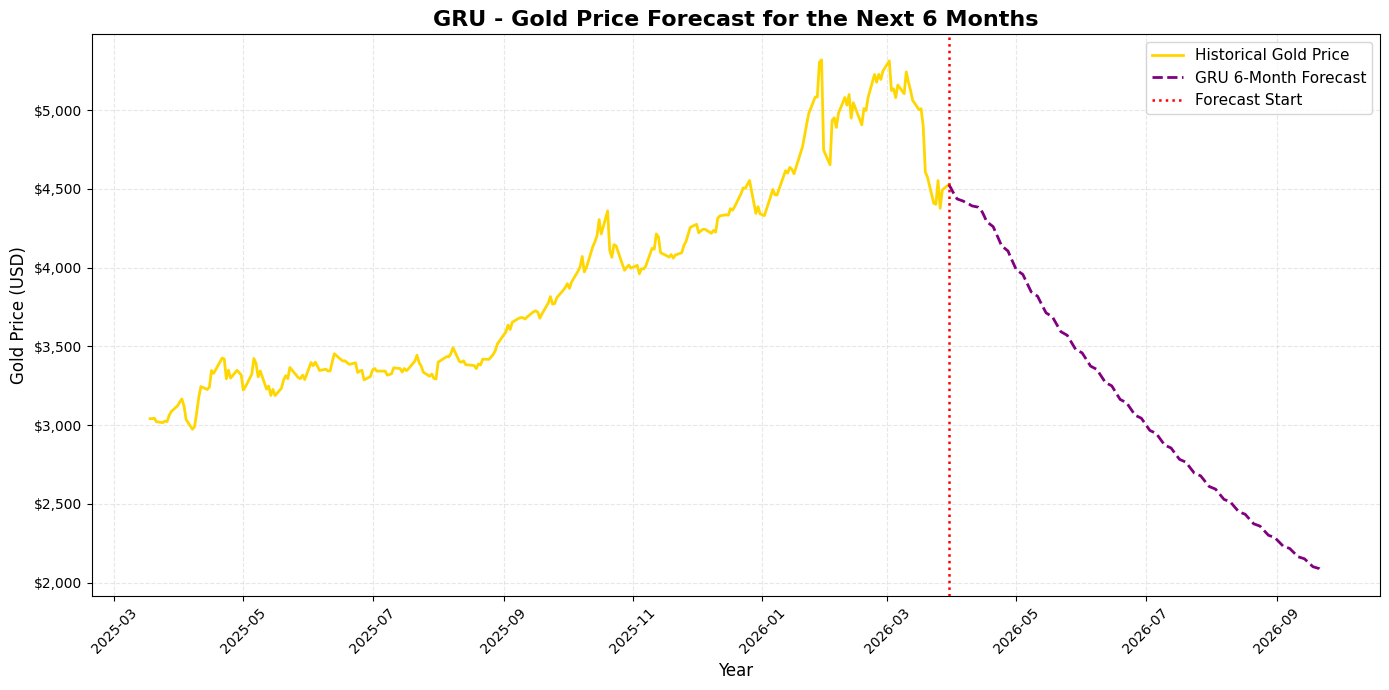

In [64]:
# GRU - 6 MONTH GOLD PRICE FORECAST GRAPH

# Select the most recent 260 historical observations
historical_gold_gru = dataset["Gold"].iloc[-260:]

# Connect the final historical gold price to the forecast
forecast_plot_dates_6m_gru = (
    [historical_gold_gru.index[-1]] + list(forecast_6m_gru.index)
)

forecast_plot_prices_6m_gru = (
    [historical_gold_gru.iloc[-1]] + list(forecast_6m_gru.values)
)

# Create the figure
plt.figure(figsize=(14, 7))

# Plot historical gold closing prices
plt.plot(
    historical_gold_gru.index,
    historical_gold_gru.values,
    label="Historical Gold Price",
    color="gold",
    linewidth=2
)

# Plot GRU 6-month forecast
plt.plot(
    forecast_plot_dates_6m_gru,
    forecast_plot_prices_6m_gru,
    label="GRU 6-Month Forecast",
    color="purple",
    linewidth=2,
    linestyle="--"
)

# Mark the beginning of the forecast period
plt.axvline(
    x=historical_gold_gru.index[-1],
    color="red",
    linestyle=":",
    linewidth=1.8,
    label="Forecast Start"
)

# Add graph title and axis labels
plt.title(
    "GRU - Gold Price Forecast for the Next 6 Months",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Gold Price (USD)", fontsize=12)

# Format gold prices in USD
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

# Add legend and grid
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)

# Rotate date labels
plt.xticks(rotation=45)

# Improve layout
plt.tight_layout()

# Display the graph
plt.show()
